<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_EncryptedTraffic_Ranjan2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM for encrypted-traffic analysis (QryptoNet): Ranjan et al. (2025) step by step

This notebook re-implements, runs and checks the method of

> Ronit Ranjan, Yuvraj Kumar, Mohana and Varun Agarwal, "QryptoNet: Quantum Support Vector Machine for Encrypted Network Traffic Analysis
> using Quantum Machine Learning (QML)", *2025 International Conference on Sustainable Communication Networks and Application (ICSCN)*,
> pp. 374-379, IEEE, 2025. DOI 10.1109/ICSCN67106.2025.11308614

The paper publishes no code and gives few numbers. Everything below is written from its six-page description, with the software stack the paper
names: **Qiskit** quantum-kernel machinery (a parameterised feature-map circuit, state fidelities as kernel values, a classical SVM on top) simulated on a classical backend.

**What the notebook does.**
1. Downloads **CIC-IDS2017**, the dataset the paper uses, from a public Hugging Face mirror, and reduces it to 16 *flow-metadata* features of the kind the paper lists (packet size mean / std, inter-arrival times, duration, packet count, direction ratio, ...). No payload is used.
2. Builds a 4-qubit QSVM two ways (the paper mentions both encodings): **amplitude encoding** of the 16 normalised features on 4 qubits (the paper's main encoding) and **angle encoding** of 4 PCA components with a Qiskit `zz_feature_map` (its "hardware friendly" alternative).
3. Trains classical baselines on exactly the same inputs: SVM (RBF and linear) and Random Forest.
4. Repeats everything on **two tasks**: *all* CIC-IDS2017 flows (benign vs the nine attack families), and the subset that really travels over **encrypted-protocol ports** (SSH, HTTPS, ...), because the CIC-IDS2017 flow files carry no TLS fields.
5. Re-creates the paper's Table I (accuracy, false positive rate, latency per flow), a 10-fold cross-validation, and a small noise-aware simulation (depolarising + readout noise) for the latency claim; then prints the paper's numbers next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned versions; if Colab asks to restart the session, restart and run all again. No GPU and no quantum-cloud account are needed. The data mirror is public (no token needed); if you have a Hugging Face token put it in Colab *Secrets* as `HF_TOKEN` (it is read from there or from the environment, never typed into the notebook).

**Runtime.** `FAST_MODE = True` is a class demo (about 1,200 flows per task, one seed): about 10 minutes on a shared laptop CPU after the one-off data scan. `FAST_MODE = False` is the larger run (4,000 flows per task, five seeds, 10-fold CV, larger noise study): about 27 minutes on the same machine (13 of them for the models of Section 4). The first execution also downloads and scans the 885 MB of CIC-IDS2017 CSV files once (a few minutes); the reduced pool is cached.

**What you get at the end.** Real-data exploration plots, the drawn circuits, a table of accuracy / precision / recall / F1 / false-positive rate for every model, confusion matrices, the paper's Table I redrawn, and a line-by-line verdict on the paper's claims.

## The paper in one page

**Problem.** TLS/SSL hides payloads, so signature and deep-packet-inspection tools go blind. QryptoNet classifies encrypted flows as benign or malicious from **metadata only**: packet-size mean and standard deviation, min / max / mean inter-arrival time, flow duration, packet count, direction ratio and TLS handshake fields (version, cipher suite).

**Decision.** Binary: malicious vs benign flow. Metrics: accuracy, false-positive rate (benign flagged malicious) and latency per flow.

**Method.** (Section III-D) Normalised feature vectors are encoded into quantum states by **amplitude encoding** (d features into d amplitudes, log2(d) qubits) or, for constrained hardware, **angle encoding** with Pauli rotations. A parameterised feature-map circuit gives kernel values as state fidelities `K(x, y) = |<phi(x)|phi(y)>|^2`; a classical SVM is trained on that kernel (Qiskit's quantum-kernel framework, simulated; "4-qubit kernel depth", noise-aware simulator with readout and depolarising noise). Around the QSVM the paper describes a "quantum entropy analyser" (covert channels) and a "post-quantum TLS handshake verifier" (cipher-suite compliance); neither is specified as an algorithm.

**Data.** CIC-IDS2017: "encrypted sessions using TLS/SSL were parsed and aggregated into flow level records". No sample size, split, kernel hyper-parameters or classical-SVM settings are given. Table I mentions 10-fold cross-validation.

**Claims to check.**

| # | Claim | Where |
|---|---|---|
| 1 | QSVM detection accuracy 97.1 % (abstract: 97.3 %) | Table I, abstract |
| 2 | Classical SVM on the same features: 92.3 %; SVM and Random Forest "plateaued between 91-93 %" | Table I, Sec. IV-A |
| 3 | QSVM false-positive rate 2.8 % ("below 3 %"); classical SVM 6.5 % | Table I |
| 4 | Latency per flow 1.6 s (QSVM) vs 1.2 s (classical SVM), "under 2 s", 4-qubit kernel on a noise-aware simulator | Table I, Sec. IV |
| 5 | TLS compliance detection 99.9 % (verifier module) | Table I |
| 6 | Covert-channel detection 94.3 % (QSVM / entropy module) vs 78.2 % (classical SVM) | Table I |
| 7 | QSVM beats SVM and Random Forest | Sec. IV-A |
| 8 | (Sec. III-C also states "above 99 %", which contradicts the 97.1 % of Table I) | Sec. III-C |

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | CIC-IDS2017, "encrypted sessions ... parsed" (sample size not given) | CIC-IDS2017 flow CSVs from the public mirror `c01dsnap/CIC-IDS2017` (2.83 M flows). The CSVs have **no TLS handshake fields** and no encrypted-flow flag, so two tasks are run: **E1** all flows, **E2** flows whose destination port is an encrypted-protocol port (22, 443, 444, 465, 563, 636, 989, 990, 992, 993, 995, 8443) # CHOICE |
| Features | packet size mean / std, IAT min / max / mean, duration, packet count, direction ratio, TLS version / cipher suite | The 8 named flow features (`Packet Length Mean/Std`, `Flow IAT Min/Max/Mean`, `Flow Duration`, total packets, direction ratio) plus 8 more metadata features (per-direction packet length means, byte totals, bytes/s, packets/s, per-direction IAT means) so that 16 features fill the 16 amplitudes of 4 qubits # CHOICE. TLS fields do not exist in the data and are **not** used |
| Labels | malicious vs benign | benign = 0, every attack family = 1; the attack family is kept for plots and per-family recall |
| Sample | not given | class-balanced sample, `N_TOTAL` flows per task (50 % benign, the attack half spread evenly over the attack families), stratified 70/30 split # CHOICE |
| Cleaning | not given | drop NaN / inf and duplicate rows; `log1p` of the non-negative features (heavy-tailed) # CHOICE |
| Amplitude encoding | normalised vector -> amplitudes | `log1p` -> scaler fitted on training data (min-max or z-score, chosen on a validation split) -> L2 normalisation -> `raw_feature_vector(16)` on 4 qubits # CHOICE |
| Angle encoding | "Pauli rotations" | 4 PCA components (fitted on the training split) scaled to [0, pi], times a bandwidth chosen on a validation split, into `zz_feature_map(4, reps=2, entanglement="linear")` # CHOICE |
| Kernel | fidelity kernel, Qiskit | `FidelityStatevectorKernel` + `QSVC`, checked against the same kernel computed by hand and fed to `SVC(kernel="precomputed")` |
| Classical SVM | "classical SVM on the same feature set", settings not given | RBF SVM (C and gamma tuned on the same validation split), default RBF SVM, linear SVM; on the 16 standardised features and on exactly the quantum inputs. Random Forest (200 trees) |
| Noise | "readout and depolarising noise based on IBM QPU specifications" | custom Aer noise model: 0.05 % depolarising per single-qubit gate, 1 % per CX, 2 % readout flip # CHOICE (typical IBM values, not a specific device) |
| Entropy analyser, PQTLS verifier | described, no algorithm or data | **not implemented**: no data and no specification; claims 5 and 6 are marked "cannot be checked" |
| Hardware | none (simulator) | none (simulator) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever Qiskit machine learning is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub pyarrow
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit already present; skipping pip install.")

Qiskit already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False      # True: class demo, 1,200 flows per task, one seed. False: 4,000 flows per task, five seeds, bigger noise study.
SEED      = 42          # CHOICE: the paper gives no seed
DATA_DIR  = "data_qc189"      # downloaded data are cached here (scratch folder; never commit it)
LOCAL_CIC_DIR = None    # optional: folder holding the 8 CIC-IDS2017 CSVs, to skip the download
IBM_TOKEN = ""          # unused: the paper reports simulator runs only

N_QUBITS   = 4          # paper: 4-qubit kernel; 16 amplitudes = 2**4 and 4 PCA angles
N_FEATURES = 2 ** N_QUBITS
TEST_SIZE  = 0.30       # CHOICE: stratified 70/30 split
VAL_FRAC   = 0.25       # share of the TRAINING split held out to choose bandwidth / C / gamma (the test split is never used for tuning)
FM_REPS, ENTANGLEMENT = 2, "linear"     # CHOICE: Qiskit zz_feature_map defaults to reps=2; linear = nearest-neighbour ZZ pairs
C_GRID     = [1.0, 10.0, 100.0]          # CHOICE: the paper gives no C
GAMMA_MULT = [0.1, 0.3, 1.0, 3.0, 10.0]  # CHOICE: RBF gamma = multiple of scikit-learn's gamma="scale" of the same inputs
AMP_PREPS  = ["minmax", "standard"]     # CHOICE: how the 16 log-features are scaled before the L2 normalisation of amplitude encoding
RF_TREES   = 200
POOL_CAP   = 15_000     # cached pool: at most this many cleaned flows per (original label, encrypted-port flag)
SHOTS      = 2048       # shots of the noise-aware kernel study
P1_DEPOL, P2_DEPOL, P_READOUT = 0.0005, 0.01, 0.02     # CHOICE: depolarising error per 1-qubit gate / per CX, readout flip probability
ENC_PORTS  = [22, 443, 444, 465, 563, 636, 989, 990, 992, 993, 995, 8443]   # CHOICE: SSH, HTTPS, Heartbleed server (444), SMTPS, NNTPS, LDAPS, FTPS, IMAPS, POP3S, HTTPS-alt

if FAST_MODE:
    N_TOTAL = 1_200; SEEDS = [SEED];                               BANDWIDTHS = [0.1, 0.25, 0.5, 1.0];       N_NOISE_TRAIN, N_NOISE_TEST = 24, 12;  N_LAT = 20
else:
    N_TOTAL = 4_000; SEEDS = [SEED, SEED + 1, SEED + 2, SEED + 3, SEED + 4]; BANDWIDTHS = [0.05, 0.1, 0.25, 0.5, 1.0]; N_NOISE_TRAIN, N_NOISE_TEST = 40, 20;  N_LAT = 50
CV_FOLDS = 10           # paper, Table I: 10-fold cross-validation

# Paper-named flow features first (8), then 8 more metadata features -> 16 numbers = 16 amplitudes of 4 qubits.
RAW_COLUMNS = ["Packet Length Mean", "Packet Length Std", "Flow IAT Min", "Flow IAT Max", "Flow IAT Mean", "Flow Duration",
               "Total Fwd Packets", "Total Backward Packets", "Fwd Packet Length Mean", "Bwd Packet Length Mean",
               "Total Length of Fwd Packets", "Total Length of Bwd Packets", "Flow Bytes/s", "Flow Packets/s", "Fwd IAT Mean", "Bwd IAT Mean"]
FEATURES = ["Packet Length Mean", "Packet Length Std", "Flow IAT Min", "Flow IAT Max", "Flow IAT Mean", "Flow Duration",
            "Total Packets", "Direction Ratio", "Fwd Packet Length Mean", "Bwd Packet Length Mean",
            "Total Length of Fwd Packets", "Total Length of Bwd Packets", "Flow Bytes/s", "Flow Packets/s", "Fwd IAT Mean", "Bwd IAT Mean"]
assert len(FEATURES) == N_FEATURES
print(f"FAST_MODE={FAST_MODE} | flows per task={N_TOTAL} | seeds={SEEDS} | bandwidths={BANDWIDTHS} | noise study {N_NOISE_TRAIN} train + {N_NOISE_TEST} test flows")

FAST_MODE=False | flows per task=4000 | seeds=[42, 43, 44, 45, 46] | bandwidths=[0.05, 0.1, 0.25, 0.5, 1.0] | noise study 40 train + 20 test flows

In [3]:
import os, re, json, time, math, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, qiskit, qiskit_aer, qiskit_machine_learning
from IPython.display import display
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.circuit.library import raw_feature_vector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals
warnings.filterwarnings("ignore")

algorithm_globals.random_seed = SEED
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token: the CIC-IDS2017 mirror is public, so none is needed. If you have one (e.g. for a gated mirror), put it in
# Colab Settings > Secrets as HF_TOKEN (or in the HF_TOKEN environment variable). Never paste a token into a notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
NOTEBOOK_T0 = time.time()

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-machine-learning 0.9.1


## 1. Data: CIC-IDS2017 flow records

CIC-IDS2017 (Sharafaldin et al., 2018) is five days of labelled traffic of a small enterprise testbed, summarised by CICFlowMeter into one row per flow with 78 numeric flow features and a label: `BENIGN` or one of 14 attack labels (brute force, DoS, DDoS, port scan, botnet, web attacks, infiltration, Heartbleed). The paper says it parsed "encrypted sessions using TLS/SSL" out of it; these CSV files, however, **contain no TLS fields and no encrypted flag**. What they do contain is the destination port, so this notebook marks a flow as *encrypted-protocol* when it goes to a port that carries TLS or SSH (`ENC_PORTS`, a documented choice). That gives the second task (E2).

The 8 daily files (885 MB) are streamed one at a time from the Hugging Face mirror `c01dsnap/CIC-IDS2017`, read in chunks of 200,000 rows and **deleted after reading**; only the 16 metadata columns and the destination port are kept. The cleaning of the paper is applied (NaN / inf rows and duplicate rows dropped), the **raw** label counts of the whole dataset are recorded first, and the result is reduced to a cached *pool* of at most `POOL_CAP` flows per (original label, encrypted-port flag).

In [4]:
def hf_get(repo_id, filename, subdir):
    """Download one file of a Hugging Face *dataset* repo into DATA_DIR/subdir (public repo; the token, if any, is only passed through)."""
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id, filename, repo_type="dataset", local_dir=os.path.join(DATA_DIR, subdir), token=HF_TOKEN or None)

def clean_label(s):
    """Original CIC-IDS2017 labels contain a non-ASCII dash ('Web Attack <dash> XSS'); map any odd character to '-'."""
    return re.sub(r"-{2,}", "-", re.sub(r"[^\x20-\x7e]+", "-", str(s))).strip()

CIC_REPO  = "c01dsnap/CIC-IDS2017"
CIC_FILES = ["Monday-WorkingHours.pcap_ISCX.csv", "Tuesday-WorkingHours.pcap_ISCX.csv", "Wednesday-workingHours.pcap_ISCX.csv",
             "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv", "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
             "Friday-WorkingHours-Morning.pcap_ISCX.csv", "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
             "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"]
CIC_FAMILY = {"BENIGN": "Benign", "DoS Hulk": "DoS", "DoS GoldenEye": "DoS", "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS",
              "Heartbleed": "Heartbleed", "DDoS": "DDoS", "PortScan": "PortScan", "FTP-Patator": "BruteForce", "SSH-Patator": "SSH-Patator",
              "Bot": "Botnet", "Web Attack - Brute Force": "WebAttack", "Web Attack - XSS": "WebAttack",
              "Web Attack - Sql Injection": "WebAttack", "Infiltration": "Infiltration"}        # CHOICE: 15 original labels -> 1 benign + 9 attack families

def load_cic_pool():
    """Stream the 8 daily CSVs (885 MB in total) one at a time, keep only the 16 metadata columns, and reduce them to a cached pool:
    after cleaning, at most POOL_CAP flows per (original label, encrypted-port flag). The CSV is deleted right after reading."""
    pool_f, meta_f = os.path.join(DATA_DIR, "cic2017_pool_v1.parquet"), os.path.join(DATA_DIR, "cic2017_meta_v1.json")
    if os.path.exists(pool_f) and os.path.exists(meta_f):
        return pd.read_parquet(pool_f), json.load(open(meta_f))
    rg = np.random.default_rng(SEED)
    keep_cols = RAW_COLUMNS + ["Destination Port", "Label"]
    parts, raw_counts, enc_counts, enc_ports, n_rows, t0 = [], {}, {}, {}, 0, time.time()
    for f in CIC_FILES:
        local = os.path.join(LOCAL_CIC_DIR, f) if LOCAL_CIC_DIR else None
        p = local if (local and os.path.exists(local)) else hf_get(CIC_REPO, f, "hf_cic")
        for ch in pd.read_csv(p, chunksize=200_000, low_memory=False, encoding="latin-1"):
            ch.columns = [c.strip() for c in ch.columns]
            ch["Label"] = ch["Label"].map(clean_label)
            n_rows += len(ch)
            is_enc = ch["Destination Port"].isin(ENC_PORTS)
            for k, v in ch["Label"].value_counts().items():
                raw_counts[k] = raw_counts.get(k, 0) + int(v)
            for k, v in ch.loc[is_enc, "Label"].value_counts().items():
                enc_counts[k] = enc_counts.get(k, 0) + int(v)
            for (k, port), v in ch.loc[is_enc].groupby(["Label", "Destination Port"]).size().items():
                enc_ports[f"{k}|{int(port)}"] = enc_ports.get(f"{k}|{int(port)}", 0) + int(v)
            ch = ch[keep_cols].copy()
            ch[RAW_COLUMNS] = ch[RAW_COLUMNS].apply(pd.to_numeric, errors="coerce")
            ch = ch.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()          # paper-style cleaning (Algorithm: NaN / inf / duplicates)
            ch["enc"] = ch["Destination Port"].isin(ENC_PORTS)
            for (lab, enc), g in ch.groupby(["Label", "enc"]):
                parts.append(g.sample(n=min(len(g), POOL_CAP), random_state=int(rg.integers(1 << 31))))
        if not (local and os.path.exists(local)):
            try: os.remove(p)                                                         # never keep the big CSVs
            except OSError: pass
        print(f"  {f}: done ({time.time() - t0:.0f} s)", flush=True)
    pool = pd.concat(parts, ignore_index=True).drop_duplicates(subset=RAW_COLUMNS + ["Label"])
    pool = pd.concat([g.sample(n=min(len(g), POOL_CAP), random_state=SEED) for _, g in pool.groupby(["Label", "enc"])], ignore_index=True)
    pool["family"] = pool["Label"].map(CIC_FAMILY)
    meta = dict(raw_rows=int(n_rows), raw_label_counts=raw_counts, raw_enc_label_counts=enc_counts, raw_enc_label_ports=enc_ports)
    pool.to_parquet(pool_f); json.dump(meta, open(meta_f, "w"))
    return pool, meta

t0 = time.time()
pool, meta = load_cic_pool()
print(f"pool ready in {time.time() - t0:.0f} s: {pool.shape[0]:,} cleaned flows kept out of {meta['raw_rows']:,} in the whole dataset")

pool ready in 2 s: 94,369 cleaned flows kept out of 2,830,743 in the whole dataset


## 2. Features, balanced samples, split and preprocessing

* **Features.** The 16 columns of `FEATURES`: the eight metadata features the paper names (with `Total Packets = fwd + bwd` and `Direction Ratio = fwd / (fwd + bwd)` derived from the two packet counters) plus eight more metadata features. Nothing here looks inside a payload.
* **Two tasks.** **E1**: every flow of the pool. **E2**: only flows whose destination port is in `ENC_PORTS`. In both the sample is class balanced (50 % benign; the attack half spread as evenly as possible over the attack families that exist in that task).
* **Split.** Stratified 70/30 on the attack family, `random_state = seed`.
* **Preprocessing, fitted on the training split only.**
  `log1p` of the non-negative features (CICFlowMeter's rates and times span ten orders of magnitude) -> either
  (a) *angle pipeline*: `StandardScaler` -> `PCA(4)` -> `MinMaxScaler((0, pi))` (test angles clipped to [0, pi]), or
  (b) *amplitude pipeline*: a scaler (min-max to [0, 1] or z-score, chosen on the validation split) -> division by the L2 norm, so that the 16 numbers are a unit vector = the 16 amplitudes of a 4-qubit state, or
  (c) *classical-baseline pipeline*: `StandardScaler` on the 16 log-features (the paper's "classical SVM on the same feature set").

In [5]:
def engineer(df):
    """16 metadata features (the paper's named ones first). Packet counters become 'Total Packets' and 'Direction Ratio'."""
    out = df[RAW_COLUMNS].copy()
    fwd, bwd = out.pop("Total Fwd Packets"), out.pop("Total Backward Packets")
    out["Total Packets"] = fwd + bwd
    out["Direction Ratio"] = fwd / (fwd + bwd).clip(lower=1)
    return out[FEATURES]

def waterfill(avail, total):
    """Spread `total` items over groups as evenly as possible without exceeding each group's availability."""
    quota, remaining, active = {k: 0 for k in avail}, int(total), [k for k, v in avail.items() if v > 0]
    while remaining > 0 and active:
        share = max(1, remaining // len(active))
        for k in list(active):
            take = min(share, avail[k] - quota[k], remaining)
            quota[k] += take; remaining -= take
            if quota[k] >= avail[k]: active.remove(k)
    return quota

def draw_task(pool, task, n_total, seed):
    """Class-balanced sample of a task ('E1' all flows, 'E2' encrypted-protocol ports only). Returns a DataFrame with FEATURES, family, y."""
    sub = pool if task == "E1" else pool[pool["enc"]]
    rg = np.random.default_rng(seed)
    fam = sub["family"].values
    att = {k: int(v) for k, v in sub[sub["family"] != "Benign"]["family"].value_counts().items()}
    n_ben = min(n_total // 2, int((fam == "Benign").sum()), sum(att.values()))     # balanced: never more benign than attack flows available
    quota = waterfill(att, n_ben)
    quota["Benign"] = n_ben
    idx = np.concatenate([rg.choice(np.flatnonzero(fam == k), size=q, replace=False) for k, q in quota.items() if q > 0])
    out = engineer(sub.iloc[np.sort(idx)]).reset_index(drop=True)
    out["family"] = sub["family"].values[np.sort(idx)]
    out["y"] = (out["family"] != "Benign").astype(int)
    return out

class Prep:
    """All transforms fitted on the TRAINING split only. Produces the inputs of every model of the notebook."""
    def __init__(self, seed): self.seed = seed
    def _log(self, F): return np.log1p(np.clip(np.asarray(F, float), 0.0, None))
    def fit(self, F):
        L = self._log(F)
        self.std = StandardScaler().fit(L)                                     # classical baseline + PCA input
        self.mm = MinMaxScaler((0.0, 1.0)).fit(L)                              # amplitude pipeline, option "minmax"
        Z = self.std.transform(L)
        self.pca = PCA(n_components=N_QUBITS, random_state=self.seed).fit(Z)    # angle pipeline
        self.ang = MinMaxScaler((0.0, np.pi)).fit(self.pca.transform(Z))
        self.explained = float(self.pca.explained_variance_ratio_.sum())
        return self
    @staticmethod
    def _unit(V):
        n = np.linalg.norm(V, axis=1, keepdims=True)
        V = np.where(n > 1e-12, V / np.maximum(n, 1e-12), 0.0)
        V[n[:, 0] <= 1e-12, 0] = 1.0                                           # degenerate all-zero vector -> |0000>
        return V
    def transform(self, F):
        L = self._log(F); Z = self.std.transform(L); P = self.pca.transform(Z)
        return dict(Z=Z, P=P, A=np.clip(self.ang.transform(P), 0.0, np.pi),
                    amp_minmax=self._unit(np.clip(self.mm.transform(L), 0.0, 1.0)), amp_standard=self._unit(Z))

def make_split(task, seed):
    df = draw_task(pool, task, N_TOTAL, seed)
    itr, ite = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, stratify=df["family"], random_state=seed)
    tr, te = df.iloc[itr].reset_index(drop=True), df.iloc[ite].reset_index(drop=True)
    prep = Prep(seed).fit(tr[FEATURES].values)
    return dict(task=task, seed=seed, tr=tr, te=te, ytr=tr["y"].values, yte=te["y"].values, ftr=tr["family"].values, fte=te["family"].values,
                prep=prep, Xtr=prep.transform(tr[FEATURES].values), Xte=prep.transform(te[FEATURES].values))

TASKS = {"E1": "E1 all CIC-IDS2017 flows", "E2": "E2 encrypted-protocol ports only"}
SPLITS = {}
def get_split(task, seed):
    if (task, seed) not in SPLITS: SPLITS[(task, seed)] = make_split(task, seed)
    return SPLITS[(task, seed)]

for task in TASKS:
    sp = get_split(task, SEED)
    print(f"{TASKS[task]}: {len(sp['tr'])} train / {len(sp['te'])} test flows | PCA(4) keeps {sp['prep'].explained:.1%} of the variance")
    print("   train families:", sp["tr"]["family"].value_counts().to_dict())

E1 all CIC-IDS2017 flows: 2800 train / 1200 test flows | PCA(4) keeps 90.0% of the variance
   train families: {'Benign': 1400, 'Botnet': 196, 'BruteForce': 196, 'PortScan': 195, 'DDoS': 195, 'WebAttack': 195, 'DoS': 195, 'SSH-Patator': 195, 'Infiltration': 25, 'Heartbleed': 8}


E2 encrypted-protocol ports only: 2800 train / 1200 test flows | PCA(4) keeps 92.5% of the variance
   train families: {'Benign': 1400, 'SSH-Patator': 1180, 'PortScan': 187, 'Infiltration': 25, 'Heartbleed': 8}


## Dataset Exploration and Visualisation

What the real flows look like *before* any quantum model sees them: shape, feature names, the original label values and counts, the distribution of the real classes, and 2-D scatter plots of the real training flows coloured by their ground-truth label (the attack **family** is kept, not just benign / attack). Everything comes from the downloaded CIC-IDS2017 files; no point is synthetic.

In [6]:
print("CIC-IDS2017 (whole dataset): %s flows, 78 numeric flow features + Label; the cached pool has shape %s and the columns %s" %
      (f"{meta['raw_rows']:,}", pool.shape, list(pool.columns)))
print("\n16 metadata features used by the notebook:", ", ".join(FEATURES))
print("\noriginal label values and counts (whole dataset, before any cleaning):")
print(pd.Series(meta["raw_label_counts"]).sort_values(ascending=False).to_string())
print("\nflows to an encrypted-protocol port (ENC_PORTS), original labels:")
print(pd.Series(meta["raw_enc_label_counts"]).sort_values(ascending=False).to_string())
ports = pd.Series(meta["raw_enc_label_ports"]); ports.index = pd.MultiIndex.from_tuples([tuple(k.split("|")) for k in ports.index], names=["label", "port"])
print("\nencrypted-protocol flows per (label, port):"); print(ports.sort_values(ascending=False).head(15).to_string())
print("\nattack families in the cached pool (cleaned, capped):"); print(pool.groupby(["family", "enc"]).size().unstack(fill_value=0).rename(columns={False: "other ports", True: "encrypted ports"}).to_string())
print("\nsummary of the first 8 (paper-named) features in the pool:"); print(engineer(pool).iloc[:, :8].describe().T.round(2).to_string())

CIC-IDS2017 (whole dataset): 2,830,743 flows, 78 numeric flow features + Label; the cached pool has shape (94369, 20) and the columns ['Packet Length Mean', 'Packet Length Std', 'Flow IAT Min', 'Flow IAT Max', 'Flow IAT Mean', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Flow Bytes/s', 'Flow Packets/s', 'Fwd IAT Mean', 'Bwd IAT Mean', 'Destination Port', 'Label', 'enc', 'family']

16 metadata features used by the notebook: Packet Length Mean, Packet Length Std, Flow IAT Min, Flow IAT Max, Flow IAT Mean, Flow Duration, Total Packets, Direction Ratio, Fwd Packet Length Mean, Bwd Packet Length Mean, Total Length of Fwd Packets, Total Length of Bwd Packets, Flow Bytes/s, Flow Packets/s, Fwd IAT Mean, Bwd IAT Mean

original label values and counts (whole dataset, before any cleaning):
BENIGN                        2273097
DoS Hulk                       231073

enc           other ports  encrypted ports
family                                    
Benign              15000            15000
Botnet               1337                0
BruteForce           5931                0
DDoS                15000                0
DoS                 35890                0
Heartbleed              0               11
Infiltration            0               36
PortScan              645              267
SSH-Patator             0             3153
WebAttack            2099                0

summary of the first 8 (paper-named) features in the pool:


                      count         mean          std    min        25%         50%          75%           max
Packet Length Mean  94369.0       366.85       437.94   0.00       6.20       94.50       796.73  2.077690e+03
Packet Length Std   94369.0       752.77       982.07   0.00       4.38      172.91      1564.97  4.708990e+03
Flow IAT Min        94369.0   1364294.27   9365602.34 -14.00       2.00        4.00        66.00  1.200000e+08
Flow IAT Max        94369.0  24274993.55  36267959.61 -13.00  125634.00  5000703.00  32100000.00  1.200000e+08
Flow IAT Mean       94369.0   4467335.85  10837011.08 -13.00   38939.62   796504.20   6101128.47  1.200000e+08
Flow Duration       94369.0  31820541.01  41547578.30 -13.00  177876.00  8585750.00  72232736.00  1.200000e+08
Total Packets       94369.0        22.17      1519.20   2.00       4.00        9.00        14.00  4.653860e+05
Direction Ratio     94369.0         0.61         0.21   0.12       0.49        0.55         0.67  1.000000e+00


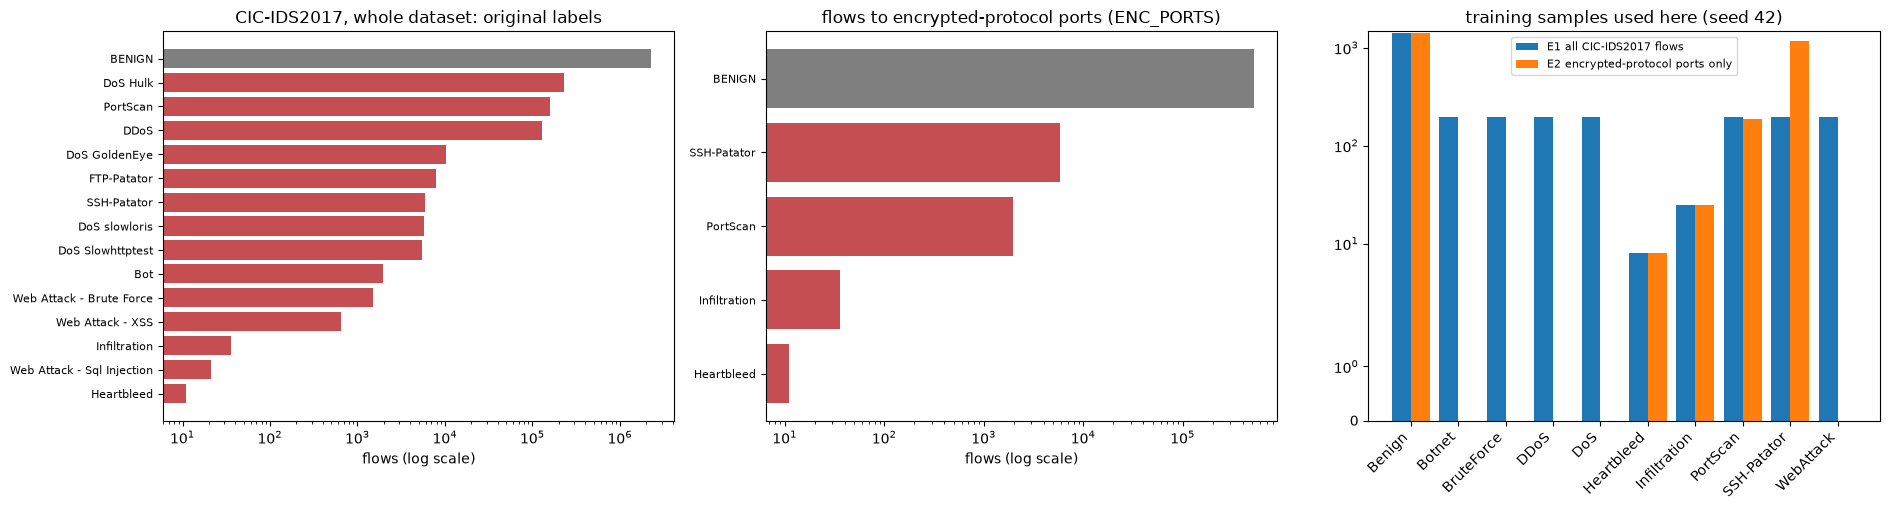

In [7]:
FAMILIES = ["Benign"] + sorted(set(pool["family"]) - {"Benign"})
COLORS = ["#7f7f7f", "#d62728", "#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b", "#e377c2", "#17becf", "#bcbd22"]
PALETTE = {f: COLORS[i % len(COLORS)] for i, f in enumerate(FAMILIES)}

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
lab = pd.Series(meta["raw_label_counts"]).sort_values()
axes[0].barh(lab.index, lab.values, color=["#7f7f7f" if k == "BENIGN" else "#c44e52" for k in lab.index]); axes[0].set_xscale("log")
axes[0].set_title("CIC-IDS2017, whole dataset: original labels"); axes[0].set_xlabel("flows (log scale)"); axes[0].tick_params(axis="y", labelsize=8)
enc = pd.Series(meta["raw_enc_label_counts"]).sort_values()
axes[1].barh(enc.index, enc.values, color=["#7f7f7f" if k == "BENIGN" else "#c44e52" for k in enc.index]); axes[1].set_xscale("log")
axes[1].set_title("flows to encrypted-protocol ports (ENC_PORTS)"); axes[1].set_xlabel("flows (log scale)"); axes[1].tick_params(axis="y", labelsize=8)
w = 0.4
for j, task in enumerate(TASKS):
    c = get_split(task, SEED)["tr"]["family"].value_counts().reindex(FAMILIES).fillna(0)
    axes[2].bar(np.arange(len(c)) + (j - 0.5) * w, c.values, w, label=TASKS[task])
axes[2].set_xticks(range(len(FAMILIES))); axes[2].set_xticklabels(FAMILIES, rotation=45, ha="right"); axes[2].set_yscale("symlog")
axes[2].set_title(f"training samples used here (seed {SEED})"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

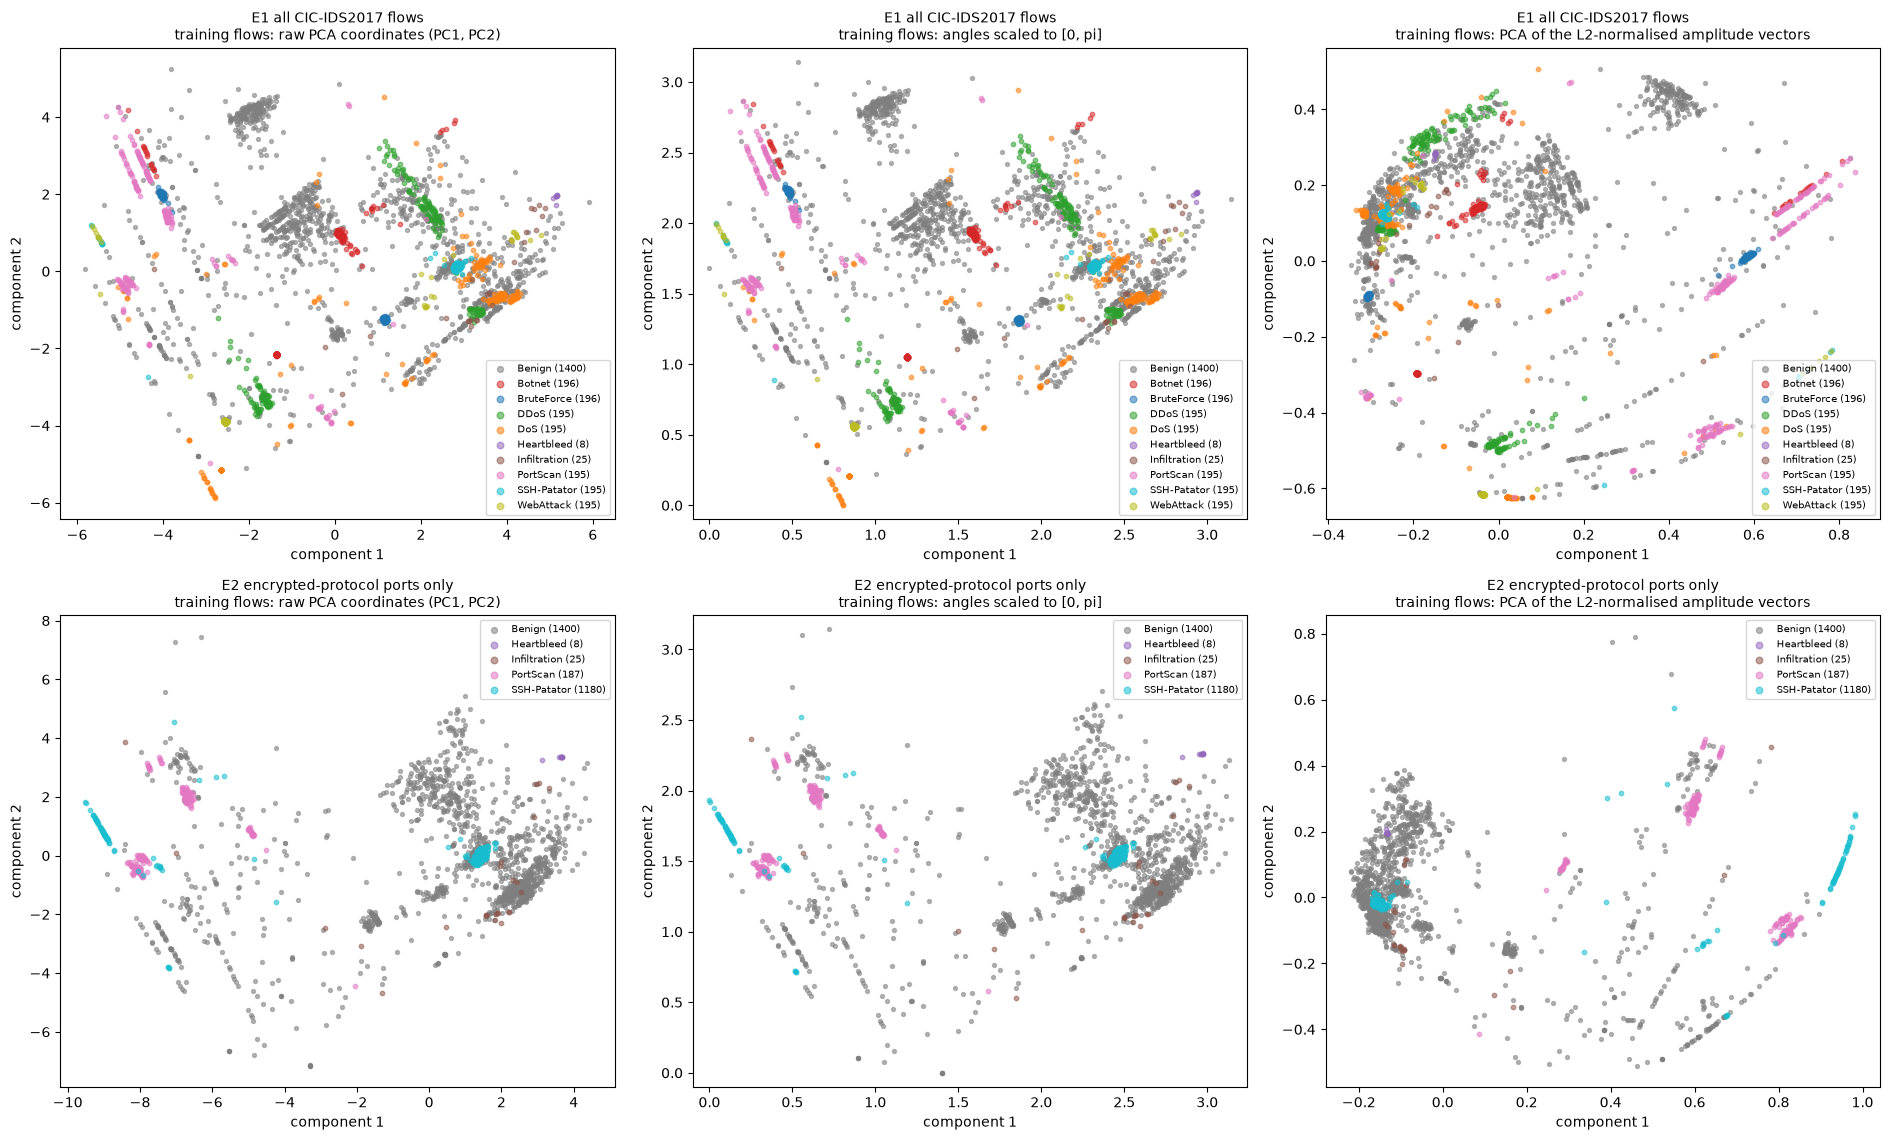

In [8]:
# 2-D scatter of the REAL training flows, coloured by the ground-truth family.
# left: first two raw PCA coordinates (PCA fitted on the training split); middle: the same two coordinates scaled to [0, pi]
# (the first two rotation angles of the angle-encoding circuit); right: first two PCA coordinates of the 16-dimensional
# amplitude vectors (the unit vectors that amplitude encoding loads into the 4 qubits).
fig, axes = plt.subplots(2, 3, figsize=(19, 11.5))
for r, task in enumerate(TASKS):
    sp = get_split(task, SEED)
    amp_pca = PCA(n_components=2, random_state=SEED).fit(sp["Xtr"]["amp_minmax"])
    views = [(sp["Xtr"]["P"][:, :2], "raw PCA coordinates (PC1, PC2)", None),
             (sp["Xtr"]["A"][:, :2], "angles scaled to [0, pi]", (-0.1, np.pi + 0.1)),
             (amp_pca.transform(sp["Xtr"]["amp_minmax"]), "PCA of the L2-normalised amplitude vectors", None)]
    for c, (XY, ttl, lim) in enumerate(views):
        ax = axes[r, c]
        for f in FAMILIES:
            m = sp["ftr"] == f
            if m.any():
                ax.scatter(XY[m, 0], XY[m, 1], s=10 if f != "Benign" else 8, alpha=0.55, color=PALETTE[f], label=f"{f} ({m.sum()})", rasterized=True)
        if lim: ax.set_xlim(*lim); ax.set_ylim(*lim)
        ax.set_title(f"{TASKS[task]}\ntraining flows: {ttl}", fontsize=10); ax.set_xlabel("component 1"); ax.set_ylabel("component 2"); ax.legend(fontsize=7, markerscale=1.5)
plt.tight_layout(); plt.show()

**What to see.** In E1 the benign flows (grey) are spread widely and overlap with several attack families in the first two components, while most attack families form compact groups (many flows of one family are nearly identical); the rare families (Infiltration, Heartbleed) are few points near the benign cloud. In E2 the attack side is dominated by SSH-Patator and PortScan flows (the only attacks of CIC-IDS2017 that go to encrypted-protocol ports in numbers); SSH brute force has a very regular packet pattern, so E2 is an easy task by construction. The classifiers use all 4 angles or all 16 amplitudes, not the two coordinates shown here.

## Quantum Circuit Architecture

The paper's quantum part is a **non-parametric kernel circuit**: a data-encoding circuit `U(x)` loads a flow into 4 qubits, and the kernel value of two flows is the fidelity `|<phi(x)|phi(y)>|^2` (the probability of measuring `0000` after `U(y)^dagger U(x)`). Nothing in the circuit is trained (0 trainable parameters); only the classical SVM on top is. The notebook runs **two encodings** and draws the circuits that are actually executed:

1. **Amplitude encoding** (the paper's main encoding): Qiskit `raw_feature_vector(16)`, bound to a *real* normalised flow of the training split, then transpiled to the hardware basis `{rz, sx, cx}` so that the actual gate count and depth appear.
2. **Angle encoding**: `zz_feature_map(4, reps=2, entanglement="linear")` (Hadamards, `P(2 x_i)` rotations and `CX - P - CX` ZZ interactions on neighbouring qubits), the `FidelityStatevectorKernel` feature map.
3. The **compute-uncompute kernel circuit** `U(y)^dagger U(x)` with measurement, used by the noise-aware simulation (Section 8).

Assumptions where the paper is silent: it names neither the feature-map circuit nor its depth ("4-qubit kernel depth", "parameterised quantum feature map circuit"), so the `ZZFeatureMap` of Havlicek et al. (the default feature map of Qiskit's quantum-kernel tutorials) with its default two repetitions and nearest-neighbour entanglement is used; for amplitude encoding the exact state-preparation circuit of Qiskit is used (an NISQ device would need about this many gates, see the printed depth).

flow used in the drawings: family = Benign


amplitude encoding, raw_feature_vector(16), as defined     qubits=4 | depth=  1 | data parameters=16 | trainable parameters=0 | gates={'ParameterizedInitialize': 1}
amplitude encoding, bound to a real flow, in {rz,sx,cx}    qubits=4 | depth= 50 | data parameters= 0 | trainable parameters=0 | gates={'rz': 26, 'sx': 21, 'cx': 11, 'reset': 4}
angle encoding, zz_feature_map(4, reps=2, linear), as defined qubits=4 | depth= 19 | data parameters= 4 | trainable parameters=0 | gates={'p': 14, 'cx': 12, 'h': 8}
angle encoding, bound to a real flow, in {rz,sx,cx}        qubits=4 | depth= 21 | data parameters= 0 | trainable parameters=0 | gates={'rz': 22, 'cx': 12, 'sx': 8}
compute-uncompute kernel circuit U(y)^dagger U(x) + measure qubits=4 | depth= 39 | data parameters= 8 | trainable parameters=0 | gates={'p': 28, 'cx': 24, 'h': 16, 'measure': 4, 'barrier': 1}

Figure 1: amplitude encoding of one real flow (16 amplitudes on 4 qubits), transpiled to {rz, sx, cx}


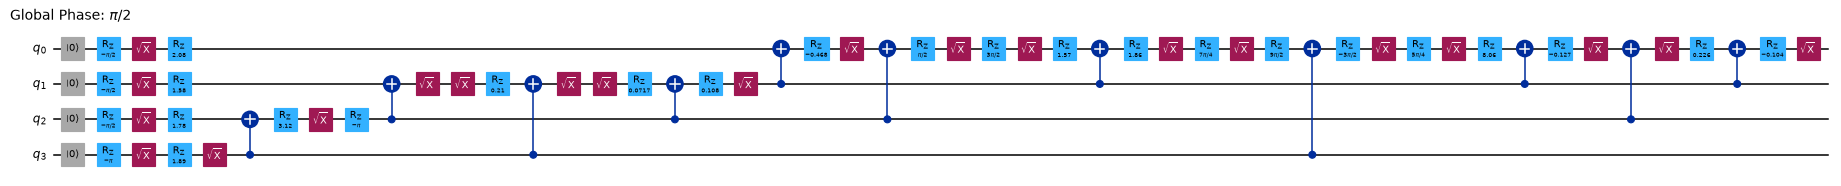

In [9]:
from IPython.display import display
FM_ZZ = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT)         # the executed angle-encoding feature map
FM_AMP = raw_feature_vector(N_FEATURES)                                           # the executed amplitude-encoding feature map

sp0 = get_split("E1", SEED)
x_angles = sp0["Xtr"]["A"][0]; x_amp = sp0["Xtr"]["amp_minmax"][0]               # a REAL training flow (its family: see below)
print("flow used in the drawings: family =", sp0["ftr"][0])

amp_bound = FM_AMP.assign_parameters(x_amp)
amp_basis = transpile(amp_bound, basis_gates=["rz", "sx", "cx"], optimization_level=1, seed_transpiler=SEED)
zz_bound = FM_ZZ.assign_parameters(x_angles)
zz_basis = transpile(zz_bound, basis_gates=["rz", "sx", "cx"], optimization_level=1, seed_transpiler=SEED)
fx = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT, parameter_prefix="x")
fy = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT, parameter_prefix="y")
KC = fx.compose(fy.inverse()); KC.measure_all()

def stats(qc, label, trainable=0):
    print(f"{label:58s} qubits={qc.num_qubits} | depth={qc.depth():3d} | data parameters={qc.num_parameters:2d} | trainable parameters={trainable} | gates={dict(qc.count_ops())}")
stats(FM_AMP, "amplitude encoding, raw_feature_vector(16), as defined")
stats(amp_basis, "amplitude encoding, bound to a real flow, in {rz,sx,cx}")
stats(FM_ZZ, "angle encoding, zz_feature_map(4, reps=2, linear), as defined")
stats(zz_basis, "angle encoding, bound to a real flow, in {rz,sx,cx}")
stats(KC, "compute-uncompute kernel circuit U(y)^dagger U(x) + measure")

# the drawn circuits are the executed ones: their states equal the encoded vectors (up to a global phase)
assert np.allclose(Statevector(amp_bound).data, x_amp) and abs(np.vdot(Statevector(amp_basis).data, x_amp)) > 1 - 1e-9
assert abs(np.vdot(Statevector(zz_basis).data, Statevector(zz_bound).data)) > 1 - 1e-9
print("\nFigure 1: amplitude encoding of one real flow (16 amplitudes on 4 qubits), transpiled to {rz, sx, cx}")
display(amp_basis.draw("mpl", fold=-1, scale=0.55))

Figure 2: angle encoding, zz_feature_map(4, reps=2, entanglement='linear') with its data parameters x[0..3]


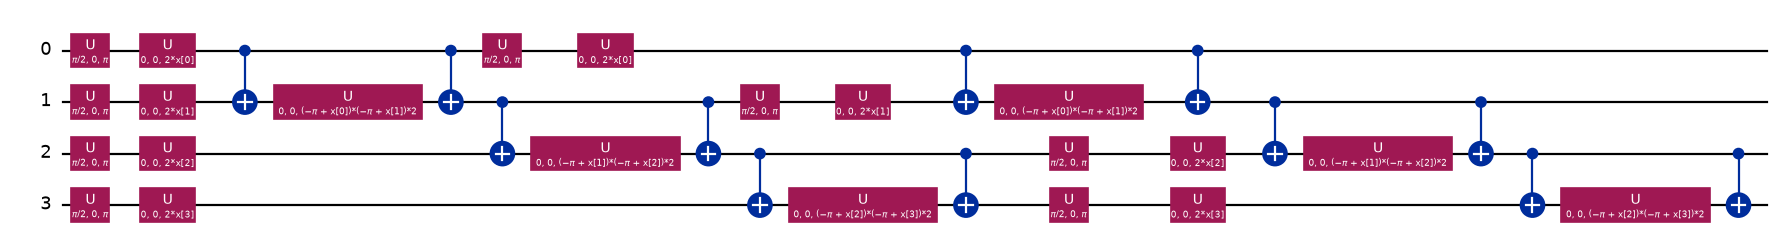


Figure 3: the same feature map bound to the four angles of a real flow and transpiled to {rz, sx, cx}


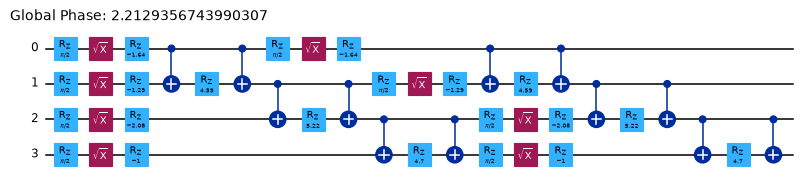


Figure 4: compute-uncompute kernel circuit U(y)^dagger U(x) with measurement of all qubits (run per pair of flows in Section 8)


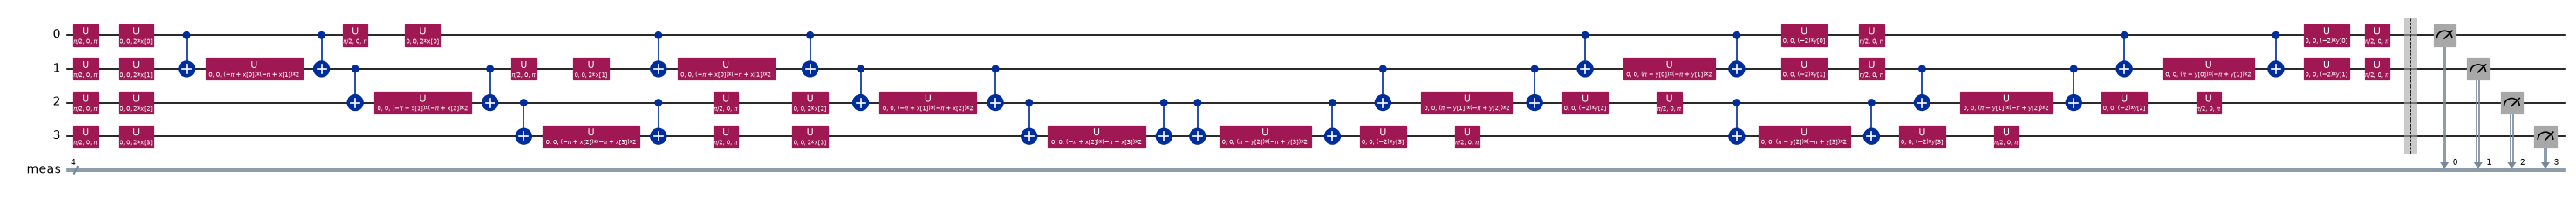

In [10]:
print("Figure 2: angle encoding, zz_feature_map(4, reps=2, entanglement='linear') with its data parameters x[0..3]")
display(FM_ZZ.decompose().draw("mpl", fold=-1, scale=0.8))
print("\nFigure 3: the same feature map bound to the four angles of a real flow and transpiled to {rz, sx, cx}")
display(zz_basis.draw("mpl", fold=-1, scale=0.55))
print("\nFigure 4: compute-uncompute kernel circuit U(y)^dagger U(x) with measurement of all qubits (run per pair of flows in Section 8)")
display(KC.decompose().draw("mpl", fold=-1, scale=0.6))

## 3. The quantum kernels: three implementations that must agree

`K(x, y) = |<phi(x)|phi(y)>|^2` is computed by

1. **Qiskit `FidelityStatevectorKernel`** (the reference: exact statevectors of the executed circuit, every pair one by one);
2. **by hand**: `Statevector(circuit.assign_parameters(x))` for every flow, then `|<a|b>|^2` as one matrix product;
3. **a vectorised NumPy simulation of the angle circuit** (the gate list of `zz_feature_map`: `H`, phases `P(2 x_i)`, and the ZZ phases `2 (pi - x_i)(pi - x_j)` on the parity of neighbouring qubits), used for the big Gram matrices because the Qiskit class needs minutes per few-thousand-flow matrix. Its output is asserted equal to (1) and (2). The amplitude kernel needs no simulation at all: the state *is* the normalised vector, so `K = (x . y)^2`.

Then `QSVC(quantum_kernel=...)` is compared with `SVC(kernel="precomputed")` on the hand-computed kernel. The paper uses the former ("Qiskit's quantum kernel framework").

In [11]:
BITS = ((np.arange(2 ** N_QUBITS)[:, None] >> np.arange(N_QUBITS)) & 1).astype(float)      # bit i of basis state k = qubit i (Qiskit little-endian)
HN = np.array([[1.0]])
for _ in range(N_QUBITS): HN = np.kron(HN, np.array([[1, 1], [1, -1]]) / np.sqrt(2))      # H on every qubit
PAIRS = [(i, i + 1) for i in range(N_QUBITS - 1)] if ENTANGLEMENT == "linear" else [(i, j) for i in range(N_QUBITS) for j in range(i + 1, N_QUBITS)]

def states_zz(A, scale=1.0, reps=FM_REPS):
    """Exact statevectors of zz_feature_map for every row of A (angles), as a (N, 2**n) complex array (global phase may differ from Qiskit's)."""
    X = scale * np.asarray(A, float)
    phase = 2.0 * X @ BITS.T                                                  # P(2 x_i) on qubit i
    for i, j in PAIRS:                                                        # CX P(2 (pi-x_i)(pi-x_j)) CX = phase on the parity of qubits i, j
        phase += (2.0 * (np.pi - X[:, i]) * (np.pi - X[:, j]))[:, None] * np.abs(BITS[:, i] - BITS[:, j])[None, :]
    D = np.exp(1j * phase)
    psi = D * HN[:, 0][None, :]                                               # H|0..0> then diagonal phases
    for _ in range(reps - 1): psi = (psi @ HN.T) * D
    return psi

def gram(SA, SB): return np.abs(SA.conj() @ SB.T) ** 2

rg = np.random.default_rng(SEED)
XA, XB = sp0["Xtr"]["A"][rg.choice(len(sp0["ytr"]), 40, replace=False)], sp0["Xtr"]["A"][rg.choice(len(sp0["ytr"]), 30, replace=False)]
for s in (1.0, 0.5):
    t0 = time.perf_counter(); K_fsk = FidelityStatevectorKernel(feature_map=FM_ZZ).evaluate(s * XA, s * XB); t_fsk = time.perf_counter() - t0
    SA = np.array([Statevector(FM_ZZ.assign_parameters(s * x)).data for x in XA]); SB = np.array([Statevector(FM_ZZ.assign_parameters(s * x)).data for x in XB])
    K_hand = np.abs(SA.conj() @ SB.T) ** 2
    K_np = gram(states_zz(XA, s), states_zz(XB, s))
    assert np.allclose(K_fsk, K_hand, atol=1e-10) and np.allclose(K_fsk, K_np, atol=1e-10), "kernel implementations disagree"
    print(f"angle encoding, scale {s}: FidelityStatevectorKernel == by-hand Statevector == NumPy simulation (max |diff| {np.abs(K_fsk - K_np).max():.1e}); "
          f"Qiskit class {1e6 * t_fsk / K_fsk.size:.0f} microseconds per pair")
VA, VB = sp0["Xtr"]["amp_minmax"][:40], sp0["Xtr"]["amp_minmax"][40:70]
K_fsk_a = FidelityStatevectorKernel(feature_map=FM_AMP).evaluate(VA, VB)
assert np.allclose(K_fsk_a, (VA @ VB.T) ** 2, atol=1e-10)
print("amplitude encoding: FidelityStatevectorKernel == (x . y)^2 (closed form), max |diff| %.1e" % np.abs(K_fsk_a - (VA @ VB.T) ** 2).max())

# QSVC (Qiskit) vs SVC on the precomputed kernel, on a small slice of real flows
idx_tr, idx_te = np.arange(120), np.arange(120, 180)
for name, fm, ftr, fte, kfun in (("angle (ZZ)", FM_ZZ, sp0["Xtr"]["A"], sp0["Xtr"]["A"], lambda a, b: gram(states_zz(a), states_zz(b))),
                                 ("amplitude", FM_AMP, sp0["Xtr"]["amp_minmax"], sp0["Xtr"]["amp_minmax"], lambda a, b: (a @ b.T) ** 2)):
    ytr_s, yte_s = sp0["ytr"][idx_tr], sp0["ytr"][idx_te]
    t0 = time.perf_counter(); qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fm), C=10.0).fit(ftr[idx_tr], ytr_s); p_q = qsvc.predict(fte[idx_te]); t_q = time.perf_counter() - t0
    p_s = SVC(kernel="precomputed", C=10.0).fit(kfun(ftr[idx_tr], ftr[idx_tr]), ytr_s).predict(kfun(fte[idx_te], ftr[idx_tr]))
    print(f"{name:11s}: QSVC accuracy {accuracy_score(yte_s, p_q):.3f} ({t_q:.1f} s) | SVC(precomputed) accuracy {accuracy_score(yte_s, p_s):.3f} | identical predictions: {bool((p_q == p_s).all())}")
    assert (p_q == p_s).mean() > 0.97
T_FSK_PAIR = t_fsk / K_fsk.size

angle encoding, scale 1.0: FidelityStatevectorKernel == by-hand Statevector == NumPy simulation (max |diff| 1.3e-15); Qiskit class 1865 microseconds per pair


angle encoding, scale 0.5: FidelityStatevectorKernel == by-hand Statevector == NumPy simulation (max |diff| 2.8e-15); Qiskit class 3792 microseconds per pair


amplitude encoding: FidelityStatevectorKernel == (x . y)^2 (closed form), max |diff| 6.7e-16


angle (ZZ) : QSVC accuracy 0.900 (16.3 s) | SVC(precomputed) accuracy 0.900 | identical predictions: True


amplitude  : QSVC accuracy 0.733 (17.9 s) | SVC(precomputed) accuracy 0.733 | identical predictions: True


## 4. Training: quantum-kernel SVMs and classical baselines

For every task and seed the following models are fitted on the training split and scored on the test split (attack = positive class):

| Model | Inputs |
|---|---|
| **QSVM amplitude** (QryptoNet main) | the 16 L2-normalised amplitudes; kernel `(x . y)^2`; scaler option and `C` chosen on the validation split |
| **QSVM angle (ZZ)** | the 4 PCA angles times a bandwidth chosen on the validation split; `zz_feature_map` kernel; `C` chosen on the validation split |
| SVM RBF (4 angles, defaults) / (4 angles, tuned) | exactly the angles of the angle QSVM |
| SVM RBF (16 amplitudes, tuned), SVM linear (16 amplitudes) | exactly the amplitude vectors of the amplitude QSVM |
| **SVM RBF (16 standardised features, tuned)** | the paper's "classical SVM trained on the same feature set" |
| Random Forest (4 angles), Random Forest (16 features) | 200 trees |

Hyper-parameters (bandwidth, scaler option, `C`, `gamma`) are chosen on a stratified inner split of the **training** data (75 / 25) with the same grid size for the quantum and the classical models, so that neither kernel gets a tuning advantage. The test split is never used for tuning. Metrics: accuracy, precision, recall, F1, **false-positive rate** (benign flagged malicious), ROC-AUC, training time (kernel construction + fit + prediction, without the search).

In [12]:
def metric_dict(y, p, score=None):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return dict(acc=accuracy_score(y, p), prec=precision_score(y, p, zero_division=0), rec=recall_score(y, p), f1=f1_score(y, p, zero_division=0),
                fpr=fp / max(fp + tn, 1), auc=(roc_auc_score(y, score) if score is not None and len(np.unique(y)) > 1 else np.nan))

def inner_split(y, seed): return train_test_split(np.arange(len(y)), test_size=VAL_FRAC, stratify=y, random_state=seed)

def tune_precomputed(Ks, y, seed):
    """Ks: dict option -> training Gram matrix. Returns (best option, best C, validation accuracy) by accuracy on the inner validation split."""
    itr, iva = inner_split(y, seed); best = None
    for opt, K in Ks.items():
        for C in C_GRID:
            acc = accuracy_score(y[iva], SVC(kernel="precomputed", C=C).fit(K[np.ix_(itr, itr)], y[itr]).predict(K[np.ix_(iva, itr)]))
            if best is None or acc > best[0] + 1e-12: best = (acc, opt, C)
    return best[1], best[2], best[0]

def tune_rbf(X, y, seed):
    itr, iva = inner_split(y, seed); g0 = 1.0 / (X.shape[1] * X.var()); best = None
    for C in C_GRID:
        for m in GAMMA_MULT:
            acc = accuracy_score(y[iva], SVC(kernel="rbf", C=C, gamma=g0 * m).fit(X[itr], y[itr]).predict(X[iva]))
            if best is None or acc > best[0] + 1e-12: best = (acc, C, g0 * m)
    return best[1], best[2], best[0]

def fit_eval_classic(make, Xtr, ytr, Xte, yte):
    t0 = time.perf_counter(); m = make().fit(Xtr, ytr); p = m.predict(Xte); t = time.perf_counter() - t0
    sc = m.decision_function(Xte) if hasattr(m, "decision_function") else m.predict_proba(Xte)[:, 1]
    return p, sc, t

def run_all(sp):
    ytr, yte, seed, rows, preds = sp["ytr"], sp["yte"], sp["seed"], [], {}
    def add(name, p, sc, t, info=""):
        rows.append(dict(task=sp["task"], seed=seed, model=name, t_fit=t, info=info, **metric_dict(yte, p, sc))); preds[name] = p
    Xtr, Xte = sp["Xtr"], sp["Xte"]

    # --- QSVM, amplitude encoding (QryptoNet main): kernel (x.y)^2 of the unit vectors
    Ks = {o: (Xtr["amp_" + o] @ Xtr["amp_" + o].T) ** 2 for o in AMP_PREPS}
    opt, C, vacc = tune_precomputed(Ks, ytr, seed)
    t0 = time.perf_counter(); Va, Vt = Xtr["amp_" + opt], Xte["amp_" + opt]
    Ktr = (Va @ Va.T) ** 2; m = SVC(kernel="precomputed", C=C).fit(Ktr, ytr); Kte = (Vt @ Va.T) ** 2; p = m.predict(Kte); sc = m.decision_function(Kte); t = time.perf_counter() - t0
    add("QSVM amplitude (4 qubits)", p, sc, t, f"scaler={opt}, C={C:g}, val acc {vacc:.3f}")
    # --- QSVM, angle encoding with zz_feature_map: bandwidth on the validation split
    SS = {s: states_zz(Xtr["A"], s) for s in BANDWIDTHS}
    Ks = {s: gram(S, S) for s, S in SS.items()}
    s_best, C, vacc = tune_precomputed(Ks, ytr, seed)
    t0 = time.perf_counter(); S_tr = states_zz(Xtr["A"], s_best); Ktr = gram(S_tr, S_tr); m = SVC(kernel="precomputed", C=C).fit(Ktr, ytr)
    Kte = gram(states_zz(Xte["A"], s_best), S_tr); p = m.predict(Kte); sc = m.decision_function(Kte); t = time.perf_counter() - t0
    add("QSVM angle ZZ (4 qubits)", p, sc, t, f"bandwidth={s_best:g}, C={C:g}, val acc {vacc:.3f}")
    sp.setdefault("qk", {})["zz"] = dict(s=s_best, C=C, Ktr=Ktr, Kte=Kte)
    # --- classical baselines on identical inputs
    for name, X1, X2 in (("SVM RBF (4 angles, tuned)", Xtr["A"], Xte["A"]), ("SVM RBF (16 amplitudes, tuned)", Xtr["amp_" + "minmax"], Xte["amp_" + "minmax"]),
                         ("SVM RBF (16 std features, tuned)", Xtr["Z"], Xte["Z"])):
        C, g, vacc = tune_rbf(X1, ytr, seed)
        p, sc, t = fit_eval_classic(lambda: SVC(kernel="rbf", C=C, gamma=g), X1, ytr, X2, yte); add(name, p, sc, t, f"C={C:g}, gamma={g:.3g}, val acc {vacc:.3f}")
    p, sc, t = fit_eval_classic(lambda: SVC(kernel="rbf", C=1.0, gamma="scale"), Xtr["A"], ytr, Xte["A"], yte); add("SVM RBF (4 angles, defaults)", p, sc, t, "C=1, gamma=scale")
    p, sc, t = fit_eval_classic(lambda: SVC(kernel="linear", C=1.0), Xtr["amp_minmax"], ytr, Xte["amp_minmax"], yte); add("SVM linear (16 amplitudes)", p, sc, t, "C=1")
    p, sc, t = fit_eval_classic(lambda: RandomForestClassifier(n_estimators=RF_TREES, random_state=seed, n_jobs=-1), Xtr["A"], ytr, Xte["A"], yte); add("Random Forest (4 angles)", p, sc, t, f"{RF_TREES} trees")
    p, sc, t = fit_eval_classic(lambda: RandomForestClassifier(n_estimators=RF_TREES, random_state=seed, n_jobs=-1), Xtr["Z"], ytr, Xte["Z"], yte); add("Random Forest (16 features)", p, sc, t, f"{RF_TREES} trees")
    return rows, preds

ROWS, PREDS = [], {}
t_all = time.perf_counter()
for task in TASKS:
    for seed in SEEDS:
        sp = get_split(task, seed)
        t0 = time.perf_counter(); r, p = run_all(sp); ROWS += r; PREDS[(task, seed)] = p
        print(f"{TASKS[task]} | seed {seed} | train {len(sp['ytr'])} / test {len(sp['yte'])} | {time.perf_counter() - t0:.0f} s", flush=True)
RES = pd.DataFrame(ROWS)
print(f"\nall experiments: {(time.perf_counter() - t_all) / 60:.1f} min")

def summary(res, cols=("acc", "prec", "rec", "f1", "fpr", "auc", "t_fit")):
    g = res.groupby(["task", "model"], sort=False); mean, std = g[list(cols)].mean(), g[list(cols)].std(ddof=0)
    out = mean.copy()
    for c in cols: out[c] = [f"{m:.3f} +/- {s:.3f}" if c != "t_fit" else f"{m:.2f} s" for m, s in zip(mean[c], std[c])]
    return out
SUM = summary(RES)
for task in TASKS:
    yte = get_split(task, SEED)["yte"]
    print(f"\n{TASKS[task]}   (test set: {len(yte)} flows, {yte.mean():.0%} attack; mean +/- std over {len(SEEDS)} seed(s))")
    print(SUM.loc[task].to_string())

E1 all CIC-IDS2017 flows | seed 42 | train 2800 / test 1200 | 188 s


E1 all CIC-IDS2017 flows | seed 43 | train 2800 / test 1200 | 157 s


E1 all CIC-IDS2017 flows | seed 44 | train 2800 / test 1200 | 83 s


E1 all CIC-IDS2017 flows | seed 45 | train 2800 / test 1200 | 44 s


E1 all CIC-IDS2017 flows | seed 46 | train 2800 / test 1200 | 44 s


...

E2 encrypted-protocol ports only | seed 43 | train 2800 / test 1200 | 55 s


E2 encrypted-protocol ports only | seed 44 | train 2800 / test 1200 | 62 s


E2 encrypted-protocol ports only | seed 45 | train 2800 / test 1200 | 69 s


E2 encrypted-protocol ports only | seed 46 | train 2800 / test 1200 | 41 s



all experiments: 13.0 min

E1 all CIC-IDS2017 flows   (test set: 1200 flows, 50% attack; mean +/- std over 5 seed(s))
                                              acc             prec              rec               f1              fpr              auc   t_fit
model                                                                                                                                         
QSVM amplitude (4 qubits)         0.948 +/- 0.007  0.941 +/- 0.012  0.958 +/- 0.008  0.949 +/- 0.006  0.061 +/- 0.013  0.977 +/- 0.004  3.21 s
QSVM angle ZZ (4 qubits)          0.945 +/- 0.005  0.940 +/- 0.009  0.952 +/- 0.008  0.946 +/- 0.005  0.061 +/- 0.009  0.972 +/- 0.004  3.53 s
SVM RBF (4 angles, tuned)         0.962 +/- 0.007  0.959 +/- 0.009  0.966 +/- 0.008  0.962 +/- 0.007  0.042 +/- 0.009  0.985 +/- 0.004  0.88 s
SVM RBF (16 amplitudes, tuned)    0.979 +/- 0.003  0.977 +/- 0.006  0.980 +/- 0.002  0.979 +/- 0.003  0.023 +/- 0.006  0.990 +/- 0.004  1.09 s
SVM RBF (16 std feature

### Confusion matrices and detection per attack family

Attack = positive class. The per-family table shows the share of test flows of each family that is classified correctly (for *Benign* this is the specificity = 1 - false-positive rate), for the seed `SEED`.

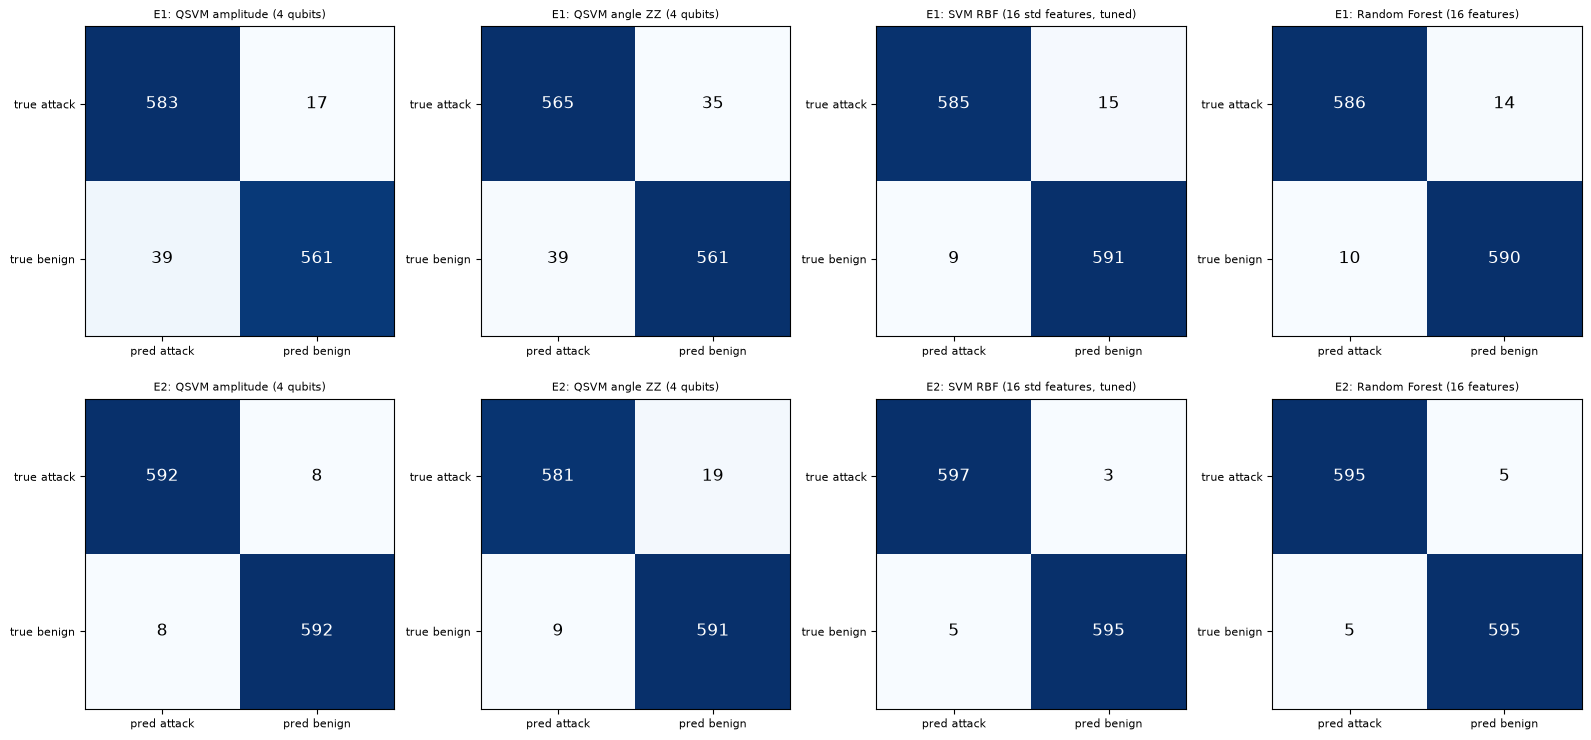

model                  QSVM amplitude (4 qubits)  QSVM angle ZZ (4 qubits)  SVM RBF (16 std features, tuned)  Random Forest (16 features)
task family       n                                                                                                                      
E1   Benign       600                      0.935                     0.935                             0.985                        0.983
     Botnet       83                       1.000                     0.976                             1.000                        1.000
     BruteForce   83                       0.988                     0.964                             0.976                        0.976
     DDoS         84                       0.988                     0.976                             0.988                        0.976
     DoS          84                       0.893                     0.833                             0.929                        0.964
     Heartbleed   3               

In [13]:
SHOW = ["QSVM amplitude (4 qubits)", "QSVM angle ZZ (4 qubits)", "SVM RBF (16 std features, tuned)", "Random Forest (16 features)"]
fig, axes = plt.subplots(len(TASKS), len(SHOW), figsize=(4.0 * len(SHOW), 3.8 * len(TASKS)))
for r, task in enumerate(TASKS):
    sp = get_split(task, SEED)
    for c, mdl in enumerate(SHOW):
        cm = confusion_matrix(sp["yte"], PREDS[(task, SEED)][mdl], labels=[1, 0]); ax = axes[r, c]; ax.imshow(cm, cmap="Blues")
        for (a, b), v in np.ndenumerate(cm): ax.text(b, a, f"{v}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=12)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["pred attack", "pred benign"], fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(["true attack", "true benign"], fontsize=8)
        ax.set_title(f"{task}: {mdl}", fontsize=8)
plt.tight_layout(); plt.show()

fam_rows = []
for task in TASKS:
    sp = get_split(task, SEED)
    for mdl in SHOW:
        p = PREDS[(task, SEED)][mdl]
        for f in sorted(set(sp["fte"])):
            m = sp["fte"] == f; fam_rows.append(dict(task=task, model=mdl, family=f, n=int(m.sum()), correct=float((p[m] == (0 if f == "Benign" else 1)).mean())))
FAM = pd.DataFrame(fam_rows)
print(FAM.pivot_table(index=["task", "family", "n"], columns="model", values="correct").round(3)[SHOW].to_string())

## 5. What the quantum kernel sees, and 10-fold cross-validation

Left: the angle-encoding kernel matrix of real training flows, sorted by family (white lines separate families); a good kernel is bright inside the diagonal blocks and dark outside. Right: the amplitude kernel `(x . y)^2` of the same flows. Below, the 10-fold cross-validation of Table I: stratified folds **inside the training split**, hyper-parameters fixed at the values chosen in Section 4 (so the cross-validation accuracy is slightly optimistic, because those values were selected on a part of the same data), for the two QSVMs and the classical SVM on the 16 standardised features.

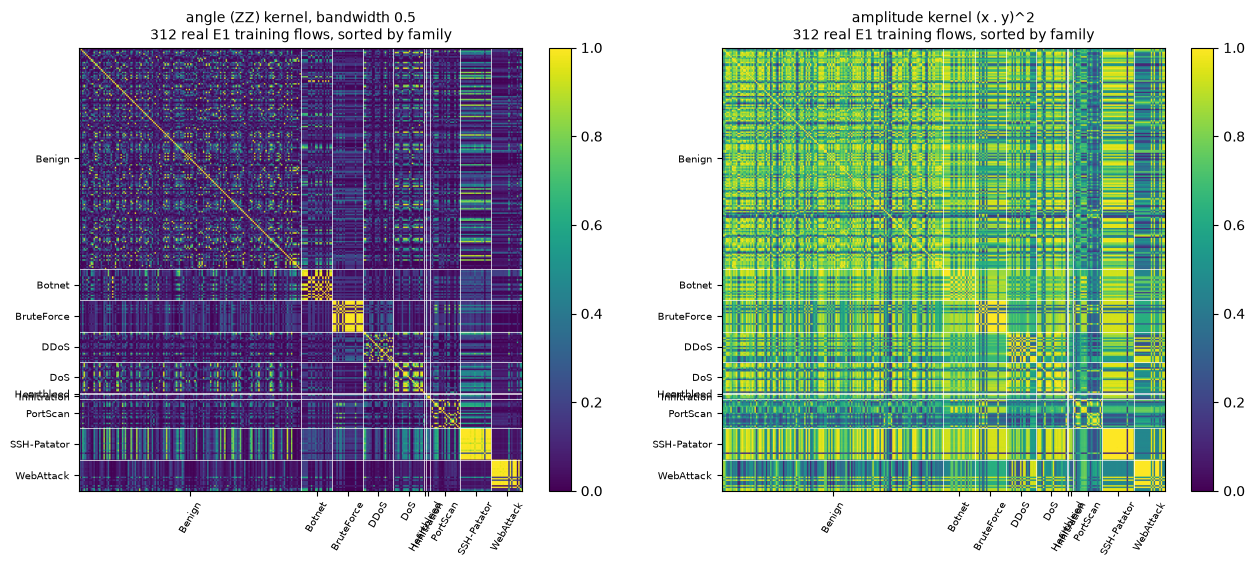

E1 all CIC-IDS2017 flows: 10-fold cross-validation on the training split
   QSVM amplitude               accuracy 0.957 +/- 0.008 | false-positive rate 0.053 +/- 0.011
   QSVM angle ZZ                accuracy 0.942 +/- 0.013 | false-positive rate 0.074 +/- 0.021
   SVM RBF (16 std features)    accuracy 0.979 +/- 0.006 | false-positive rate 0.026 +/- 0.008


E2 encrypted-protocol ports only: 10-fold cross-validation on the training split
   QSVM amplitude               accuracy 0.989 +/- 0.006 | false-positive rate 0.009 +/- 0.006
   QSVM angle ZZ                accuracy 0.979 +/- 0.006 | false-positive rate 0.011 +/- 0.009
   SVM RBF (16 std features)    accuracy 0.994 +/- 0.004 | false-positive rate 0.005 +/- 0.006
(94 s)


In [14]:
sp = get_split("E1", SEED)
order = np.argsort(sp["ftr"], kind="stable")[:: max(1, len(sp["ytr"]) // 300)]
fam_o = sp["ftr"][order]; edges = [i for i in range(1, len(fam_o)) if fam_o[i] != fam_o[i - 1]]
bounds = [0] + edges + [len(fam_o)]; mids = [(bounds[i] + bounds[i + 1]) / 2 - .5 for i in range(len(bounds) - 1)]; names_ = [fam_o[bounds[i]] for i in range(len(bounds) - 1)]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
S = states_zz(sp["Xtr"]["A"][order], sp["qk"]["zz"]["s"]); V = sp["Xtr"]["amp_minmax"][order]
for ax, K, ttl in ((axes[0], gram(S, S), f"angle (ZZ) kernel, bandwidth {sp['qk']['zz']['s']:g}"), (axes[1], (V @ V.T) ** 2, "amplitude kernel (x . y)^2")):
    im = ax.imshow(K, cmap="viridis", vmin=0, vmax=1)
    for e in edges: ax.axhline(e - .5, color="w", lw=.5); ax.axvline(e - .5, color="w", lw=.5)
    ax.set_xticks(mids); ax.set_xticklabels(names_, rotation=60, fontsize=7); ax.set_yticks(mids); ax.set_yticklabels(names_, fontsize=7)
    ax.set_title(f"{ttl}\n{len(order)} real E1 training flows, sorted by family", fontsize=10); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

def cv_scores(sp):
    ytr, seed = sp["ytr"], sp["seed"]; Xtr = sp["Xtr"]; out = {}
    skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=seed)
    ch = {r["model"]: r["info"] for r in ROWS if r["task"] == sp["task"] and r["seed"] == seed}
    opt = re.search(r"scaler=(\w+)", ch["QSVM amplitude (4 qubits)"]).group(1); Ca = float(re.search(r"C=([\d.e+-]+)", ch["QSVM amplitude (4 qubits)"]).group(1))
    Va = Xtr["amp_" + opt]; Ka = (Va @ Va.T) ** 2; Kz, Cz = sp["qk"]["zz"]["Ktr"], sp["qk"]["zz"]["C"]
    Cr = float(re.search(r"C=([\d.e+-]+)", ch["SVM RBF (16 std features, tuned)"]).group(1)); gr = float(re.search(r"gamma=([\d.e+-]+)", ch["SVM RBF (16 std features, tuned)"]).group(1))
    acc = {k: [] for k in ("QSVM amplitude", "QSVM angle ZZ", "SVM RBF (16 std features)")}; fpr = {k: [] for k in acc}
    for a, b in skf.split(np.zeros(len(ytr)), ytr):
        for name, fit_pred in (("QSVM amplitude", lambda: SVC(kernel="precomputed", C=Ca).fit(Ka[np.ix_(a, a)], ytr[a]).predict(Ka[np.ix_(b, a)])),
                               ("QSVM angle ZZ", lambda: SVC(kernel="precomputed", C=Cz).fit(Kz[np.ix_(a, a)], ytr[a]).predict(Kz[np.ix_(b, a)])),
                               ("SVM RBF (16 std features)", lambda: SVC(kernel="rbf", C=Cr, gamma=gr).fit(Xtr["Z"][a], ytr[a]).predict(Xtr["Z"][b]))):
            p = fit_pred(); acc[name].append(accuracy_score(ytr[b], p)); fpr[name].append(metric_dict(ytr[b], p)["fpr"])
    return acc, fpr

CV_RESULTS = {}
t0 = time.perf_counter()
for task in TASKS:
    acc, fpr = cv_scores(get_split(task, SEED)); CV_RESULTS[task] = (acc, fpr)
    print(f"{TASKS[task]}: {CV_FOLDS}-fold cross-validation on the training split")
    for k in acc: print(f"   {k:28s} accuracy {np.mean(acc[k]):.3f} +/- {np.std(acc[k]):.3f} | false-positive rate {np.mean(fpr[k]):.3f} +/- {np.std(fpr[k]):.3f}")
print(f"({time.perf_counter() - t0:.0f} s)")

## 6. Latency per flow

Table I reports "latency per flow": preprocessing + quantum-kernel computation + classification, 1.6 s for the QSVM and 1.2 s for the classical SVM on a "noise-aware quantum simulator" (hardware, sample size and number of support vectors unknown). Here the same quantity is measured **one flow at a time** on this machine, for the trained models of Section 4 (seed `SEED`, task E1): the raw feature row is preprocessed, a Qiskit `Statevector` of the executed encoding circuit is simulated (angle encoding; for amplitude encoding the state is the normalised vector itself), its fidelity with every training state is computed, and the SVM decides.

In [15]:
def latency_per_flow(sp, n=N_LAT):
    prep, ytr, qk = sp["prep"], sp["ytr"], sp["qk"]["zz"]; ch = {r["model"]: r["info"] for r in ROWS if r["task"] == sp["task"] and r["seed"] == sp["seed"]}
    rows = sp["te"][FEATURES].values[:n]
    # angle QSVM, circuit simulated by Qiskit
    S_tr = states_zz(sp["Xtr"]["A"], qk["s"])          # training-state matrix is precomputed once (a deployed model stores it)
    svm = SVC(kernel="precomputed", C=qk["C"]).fit(qk["Ktr"], ytr)
    def timed(fn, rep=3):                                  # best of 3 passes over the flows (the CPU is shared)
        best = 1e9
        for _ in range(rep):
            t0 = time.perf_counter()
            for r in rows: fn(r)
            best = min(best, (time.perf_counter() - t0) / len(rows))
        return best
    def f_zz(r):
        o = prep.transform(r[None, :]); sv = Statevector(FM_ZZ.assign_parameters(qk["s"] * o["A"][0])).data
        svm.predict((np.abs(S_tr.conj() @ sv) ** 2)[None, :])
    t_zz = timed(f_zz)
    # amplitude QSVM
    opt = re.search(r"scaler=(\w+)", ch["QSVM amplitude (4 qubits)"]).group(1); Ca = float(re.search(r"C=([\d.e+-]+)", ch["QSVM amplitude (4 qubits)"]).group(1))
    Va = sp["Xtr"]["amp_" + opt]; svm_a = SVC(kernel="precomputed", C=Ca).fit((Va @ Va.T) ** 2, ytr)
    def f_amp(r):
        o = prep.transform(r[None, :]); sv = Statevector(FM_AMP.assign_parameters(o["amp_" + opt][0])).data
        svm_a.predict((np.abs(Va @ sv) ** 2)[None, :])
    t_amp = timed(f_amp)
    # classical RBF SVM on the 16 standardised features
    Cr = float(re.search(r"C=([\d.e+-]+)", ch["SVM RBF (16 std features, tuned)"]).group(1)); gr = float(re.search(r"gamma=([\d.e+-]+)", ch["SVM RBF (16 std features, tuned)"]).group(1))
    rbf = SVC(kernel="rbf", C=Cr, gamma=gr).fit(sp["Xtr"]["Z"], ytr)
    def f_rbf(r):
        o = prep.transform(r[None, :]); rbf.predict(o["Z"])
    t_rbf = timed(f_rbf)
    return dict(zz=t_zz, amp=t_amp, rbf=t_rbf, n_train=len(ytr), n_flows=len(rows))

LAT = latency_per_flow(get_split("E1", SEED))
print(f"per-flow latency, one flow at a time, {LAT['n_flows']} test flows, {LAT['n_train']} training flows (E1, seed {SEED}):")
print(f"   QSVM angle ZZ (Qiskit Statevector + kernel row + SVM): {1000 * LAT['zz']:.2f} ms")
print(f"   QSVM amplitude (Qiskit Statevector + kernel row + SVM): {1000 * LAT['amp']:.2f} ms")
print(f"   classical RBF SVM (16 standardised features):          {1000 * LAT['rbf']:.2f} ms")
print(f"   ratio QSVM-ZZ / classical SVM = {LAT['zz'] / LAT['rbf']:.1f}x (paper: 1.6 s / 1.2 s = 1.3x)")

per-flow latency, one flow at a time, 50 test flows, 2800 training flows (E1, seed 42):
   QSVM angle ZZ (Qiskit Statevector + kernel row + SVM): 35.42 ms
   QSVM amplitude (Qiskit Statevector + kernel row + SVM): 47.58 ms
   classical RBF SVM (16 standardised features):          19.19 ms
   ratio QSVM-ZZ / classical SVM = 1.8x (paper: 1.6 s / 1.2 s = 1.3x)


## 7. Noise-aware simulation of the kernel circuit

The paper trained and validated "on a noise-aware quantum simulator configured with realistic readout and depolarising noise models based on IBM QPU specifications". No numbers are reported for it, but its description is enough to build one: an Aer simulator with depolarising errors on the single-qubit gates and on `CX`, and readout errors. Every kernel entry is then **estimated from `SHOTS` shots** of the compute-uncompute circuit of Figure 4 (probability of the outcome `0000`), exactly what a quantum computer would do, and an SVM is trained on that noisy kernel. Only a small number of real flows is used because every pair is a separate noisy circuit; compare the **kernel error** (mean absolute difference to the exact kernel) rather than small accuracy changes. Non-positive-semidefinite noisy kernels are repaired by clipping negative eigenvalues (what `QSVC(enforce_psd=True)` does).

In [16]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

def noise_model():
    nm = NoiseModel(basis_gates=["rz", "sx", "cx"])
    nm.add_all_qubit_quantum_error(depolarizing_error(P1_DEPOL, 1), ["sx"])
    nm.add_all_qubit_quantum_error(depolarizing_error(P2_DEPOL, 2), ["cx"])
    nm.add_all_qubit_readout_error(ReadoutError([[1 - P_READOUT, P_READOUT], [P_READOUT, 1 - P_READOUT]]))
    return nm

def kernel_from_circuits(sim, KCt, A, B, scale, sym):
    """Shot-based estimate of K(a, b) = P(0000) of U(b)^dagger U(a) for the rows of A and B (sym: A is B, upper triangle only)."""
    px, py = list(fx.parameters), list(fy.parameters)
    pairs = [(i, j) for i in range(len(A)) for j in range(len(B)) if (not sym) or j > i]
    circs = [KCt.assign_parameters(dict(zip(px + py, np.concatenate([scale * A[i], scale * B[j]])))) for i, j in pairs]
    res = sim.run(circs, shots=SHOTS).result()
    K = np.eye(len(A), len(B)) if sym else np.zeros((len(A), len(B)))
    for n_, (i, j) in enumerate(pairs):
        v = res.get_counts(n_).get("0" * N_QUBITS, 0) / SHOTS
        K[i, j] = v
        if sym: K[j, i] = v
    return K, len(circs)

def psd_clip(K):
    w, V = np.linalg.eigh((K + K.T) / 2); return (V * np.clip(w, 0, None)) @ V.T

sp = get_split("E1", SEED); s_best = sp["qk"]["zz"]["s"]; C_best = sp["qk"]["zz"]["C"]
rgn = np.random.default_rng(SEED)
def stratified_pick(y, n):
    idx = np.concatenate([rgn.choice(np.flatnonzero(y == k), size=n // 2, replace=False) for k in (0, 1)]); return rgn.permutation(idx)
itr_n, ite_n = stratified_pick(sp["ytr"], N_NOISE_TRAIN), stratified_pick(sp["yte"], N_NOISE_TEST)
A_n, At_n, y_n, yt_n = sp["Xtr"]["A"][itr_n], sp["Xte"]["A"][ite_n], sp["ytr"][itr_n], sp["yte"][ite_n]

sim_ideal = AerSimulator(seed_simulator=SEED)
sim_noisy = AerSimulator(noise_model=noise_model(), basis_gates=["rz", "sx", "cx"], seed_simulator=SEED)
KC_t = transpile(KC, sim_noisy, optimization_level=1, seed_transpiler=SEED)
print("transpiled kernel circuit: depth", KC_t.depth(), "| gates", dict(KC_t.count_ops()))

S_exact = states_zz(A_n, s_best); St_exact = states_zz(At_n, s_best)
K_exact, Kt_exact = gram(S_exact, S_exact), gram(St_exact, S_exact)
res_noise = []
for label, sim in (("exact (statevector)", None), ("shots only (noiseless Aer)", sim_ideal), ("shots + depolarising + readout noise", sim_noisy)):
    t0 = time.perf_counter()
    if sim is None: K, Kt, n_c = K_exact, Kt_exact, 0
    else:
        K, n1 = kernel_from_circuits(sim, KC_t, A_n, A_n, s_best, True); t1 = time.perf_counter()
        Kt, n2 = kernel_from_circuits(sim, KC_t, At_n, A_n, s_best, False); t_test_block = time.perf_counter() - t1; n_c = n1 + n2
    K_psd = psd_clip(K) if sim is not None else K
    m = SVC(kernel="precomputed", C=C_best).fit(K_psd, y_n); p = m.predict(Kt)
    res_noise.append(dict(kernel=label, circuits=n_c, kernel_mean_abs_error=float(np.abs(K - K_exact).mean()), min_eigenvalue=float(np.linalg.eigvalsh((K + K.T) / 2).min()),
                          accuracy=accuracy_score(yt_n, p), fpr=metric_dict(yt_n, p)["fpr"],
                          seconds_per_test_flow=(t_test_block / len(At_n)) if sim is not None else np.nan))
NOISE = pd.DataFrame(res_noise); display(NOISE.round(4))
LAT_NOISE = float(NOISE["seconds_per_test_flow"].iloc[-1])
print(f"noise-aware simulation: {LAT_NOISE:.2f} s per test flow ({N_NOISE_TRAIN} kernel circuits per flow, {SHOTS} shots each, batch-simulated on this CPU); paper: 1.6 s per flow")

transpiled kernel circuit: depth 45 | gates {'rz': 60, 'cx': 22, 'sx': 16, 'measure': 4, 'barrier': 1}


,kernel,circuits,kernel_mean_abs_error,min_eigenvalue,accuracy,fpr,seconds_per_test_flow
0,exact (statevector),0,0.0000,0.0000,0.7,0.4,NaN
1,shots only (noiseless Aer),1580,0.0050,-0.0332,0.7,0.4,2.8489
2,shots + depolarising + readout noise,1580,0.0339,0.1834,0.7,0.4,5.1815


noise-aware simulation: 5.18 s per test flow (40 kernel circuits per flow, 2048 shots each, batch-simulated on this CPU); paper: 1.6 s per flow


## 8. Paper versus this notebook

Each row is one number or statement of the paper. **reproduced** when our value is within 0.02 (two accuracy points) of the paper's, **exceeded** / **not reached** when more than 0.02 above / below, **cannot be checked** when the notebook has nothing to compare (the entropy analyser and the TLS verifier are not specified, and CIC-IDS2017 has no TLS handshake fields). The paper's single comparison (QSVM versus a classical SVM) is repeated on both tasks; the main task for the verdicts is **E1** (all CIC-IDS2017 flows, the dataset the paper names), E2 is shown alongside. Our value is the mean over `SEEDS`.

In [17]:
def ours(task, model, key): return float(RES[(RES.task == task) & (RES.model == model)][key].mean())
def ours_sd(task, model, key): return float(RES[(RES.task == task) & (RES.model == model)][key].std(ddof=0))
TOL = 0.02
def verdict(paper, val, lower_is_better=False):
    if val is None or (isinstance(val, float) and np.isnan(val)): return "cannot be checked"
    gap = 100 * (val - paper)
    if abs(val - paper) <= TOL: return f"reproduced ({gap:+.1f} points)"
    if lower_is_better: return f"not reached (rate {gap:+.1f} points higher)" if val > paper else f"exceeded (rate {-gap:.1f} points lower)"
    return f"exceeded ({gap:+.1f} points)" if val > paper else f"not reached ({gap:+.1f} points)"

QA, QZ, SVM16, RF16 = "QSVM amplitude (4 qubits)", "QSVM angle ZZ (4 qubits)", "SVM RBF (16 std features, tuned)", "Random Forest (16 features)"
rows = []
for task in TASKS:
    for q in (QA, QZ):
        rows.append(dict(task=task, claim="QSVM accuracy 97.1 % (Table I)", model=q, paper=0.971, notebook=round(ours(task, q, "acc"), 4), verdict=verdict(0.971, ours(task, q, "acc"))))
        rows.append(dict(task=task, claim="QSVM false-positive rate 2.8 % (Table I; 'below 3 %')", model=q, paper=0.028, notebook=round(ours(task, q, "fpr"), 4), verdict=verdict(0.028, ours(task, q, "fpr"), True)))
    rows.append(dict(task=task, claim="classical SVM accuracy 92.3 % (Table I)", model=SVM16, paper=0.923, notebook=round(ours(task, SVM16, "acc"), 4), verdict=verdict(0.923, ours(task, SVM16, "acc"))))
    rows.append(dict(task=task, claim="classical SVM false-positive rate 6.5 % (Table I)", model=SVM16, paper=0.065, notebook=round(ours(task, SVM16, "fpr"), 4), verdict=verdict(0.065, ours(task, SVM16, "fpr"), True)))
    rows.append(dict(task=task, claim="Random Forest accuracy 'plateaued at 91-93 %' (Sec. IV-A; midpoint 0.92)", model=RF16, paper=0.92, notebook=round(ours(task, RF16, "acc"), 4), verdict=verdict(0.92, ours(task, RF16, "acc"))))
CMP = pd.DataFrame(rows); display(CMP)

claims = []
for task in TASKS:
    for q in (QA, QZ):
        gap = ours(task, q, "acc") - ours(task, SVM16, "acc"); gap_rf = ours(task, q, "acc") - ours(task, RF16, "acc")
        sd = max(ours_sd(task, q, "acc"), ours_sd(task, SVM16, "acc"))
        v = "tie (gap within 1 point)" if abs(gap) < 0.01 else ("reproduced (same direction)" if gap > 0 else "not reproduced (opposite direction)")
        claims.append(dict(task=task, claim="QSVM more accurate than the classical SVM (paper: +4.8 points)", model=q, notebook=f"{100 * gap:+.1f} points vs SVM (seed sd {100 * sd:.1f})", verdict=v))
        v = "tie (gap within 1 point)" if abs(gap_rf) < 0.01 else ("reproduced (same direction)" if gap_rf > 0 else "not reproduced (opposite direction)")
        claims.append(dict(task=task, claim="QSVM more accurate than Random Forest (Sec. IV-A)", model=q, notebook=f"{100 * gap_rf:+.1f} points vs RF", verdict=v))
        claims.append(dict(task=task, claim="QSVM false-positive rate below the classical SVM's", model=q, notebook=f"{100 * ours(task, q, 'fpr'):.1f} % vs {100 * ours(task, SVM16, 'fpr'):.1f} %",
                           verdict="reproduced (same direction)" if ours(task, q, "fpr") < ours(task, SVM16, "fpr") - 1e-9 else ("tie" if abs(ours(task, q, 'fpr') - ours(task, SVM16, 'fpr')) < 1e-9 else "not reproduced (opposite direction)")))
claims.append(dict(task="E1", claim="latency per flow under 2 s (paper 1.6 s, noise-aware simulator)", model="QSVM angle ZZ",
                   notebook=f"{LAT_NOISE:.2f} s per flow in the noise-aware simulation ({N_NOISE_TRAIN} training flows); {1000 * LAT['zz']:.1f} ms with the exact-statevector path", verdict="reproduced (under 2 s; hardware and training size differ, so only the order of magnitude is comparable)" if LAT_NOISE < 2 else f"not reached on this machine ({LAT_NOISE:.1f} s; grows linearly with the training-set size and the CPU load; the exact-statevector path is far below 2 s)"))
claims.append(dict(task="E1", claim="QSVM slower per flow than the classical SVM (1.6 s vs 1.2 s)", model="QSVM angle ZZ", notebook=f"{LAT['zz'] / LAT['rbf']:.1f}x the classical RBF SVM", verdict="reproduced (same direction)" if LAT["zz"] > 1.05 * LAT["rbf"] else ("tie (within 5 %)" if LAT["zz"] > 0.95 * LAT["rbf"] else "not reproduced (opposite direction)")))
for task in TASKS:
    acc, fpr = CV_RESULTS[task]
    claims.append(dict(task=task, claim="10-fold cross-validation (Table I) is consistent with the single-split accuracy", model="QSVM amplitude / angle ZZ / SVM",
                       notebook="CV accuracy " + " / ".join(f"{np.mean(acc[k]):.3f}" for k in acc), verdict="reported (the paper gives no per-fold numbers)"))
claims.append(dict(task="-", claim="TLS compliance detection 99.9 % (PQTLS verifier)", model="-", notebook="no data, no algorithm", verdict="cannot be checked"))
claims.append(dict(task="-", claim="covert-channel detection 94.3 % vs 78.2 % (entropy analyser)", model="-", notebook="no data, no algorithm", verdict="cannot be checked"))
claims.append(dict(task="-", claim="'detection accuracy above 99 %' (Sec. III-C) versus 97.1 % (Table I)", model="-", notebook="the two statements of the paper contradict each other", verdict="internally inconsistent"))
CLAIMS = pd.DataFrame(claims); pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220); display(CLAIMS)
print("verdict counts:", pd.concat([CMP["verdict"], CLAIMS["verdict"]]).str.split(" \(").str[0].value_counts().to_dict())

,task,claim,model,paper,notebook,verdict
0,E1,QSVM accuracy 97.1 % (Table I),QSVM amplitude (4 qubits),0.971,0.9485,not reached (-2.3 points)
1,E1,QSVM false-positive rate 2.8 % (Table I; 'belo...,QSVM amplitude (4 qubits),0.028,0.0607,not reached (rate +3.3 points higher)
2,E1,QSVM accuracy 97.1 % (Table I),QSVM angle ZZ (4 qubits),0.971,0.9453,not reached (-2.6 points)
3,E1,QSVM false-positive rate 2.8 % (Table I; 'belo...,QSVM angle ZZ (4 qubits),0.028,0.0613,not reached (rate +3.3 points higher)
4,E1,classical SVM accuracy 92.3 % (Table I),"SVM RBF (16 std features, tuned)",0.923,0.9805,exceeded (+5.7 points)
5,E1,classical SVM false-positive rate 6.5 % (Table I),"SVM RBF (16 std features, tuned)",0.065,0.0180,exceeded (rate 4.7 points lower)
6,E1,Random Forest accuracy 'plateaued at 91-93 %' ...,Random Forest (16 features),0.920,0.9815,exceeded (+6.1 points)
7,E2,QSVM accuracy 97.1 % (Table I),QSVM amplitude (4 qubits),0.971,0.9853,reproduced (+1.4 points)
8,E2,QSVM false-positive rate 2.8 % (Table I; 'belo...,QSVM amplitude (4 qubits),0.028,0.0137,reproduced (-1.4 points)
9,E2,QSVM accuracy 97.1 % (Table I),QSVM angle ZZ (4 qubits),0.971,0.9787,reproduced (+0.8 points)


,task,claim,model,notebook,verdict
0,E1,QSVM more accurate than the classical SVM (paper: +4.8 points),QSVM amplitude (4 qubits),-3.2 points vs SVM (seed sd 0.7),not reproduced (opposite direction)
1,E1,QSVM more accurate than Random Forest (Sec. IV-A),QSVM amplitude (4 qubits),-3.3 points vs RF,not reproduced (opposite direction)
2,E1,QSVM false-positive rate below the classical SVM's,QSVM amplitude (4 qubits),6.1 % vs 1.8 %,not reproduced (opposite direction)
3,E1,QSVM more accurate than the classical SVM (paper: +4.8 points),QSVM angle ZZ (4 qubits),-3.5 points vs SVM (seed sd 0.5),not reproduced (opposite direction)
4,E1,QSVM more accurate than Random Forest (Sec. IV-A),QSVM angle ZZ (4 qubits),-3.6 points vs RF,not reproduced (opposite direction)
5,E1,QSVM false-positive rate below the classical SVM's,QSVM angle ZZ (4 qubits),6.1 % vs 1.8 %,not reproduced (opposite direction)
6,E2,QSVM more accurate than the classical SVM (paper: +4.8 points),QSVM amplitude (4 qubits),-0.5 points vs SVM (seed sd 0.3),tie (gap within 1 point)
7,E2,QSVM more accurate than Random Forest (Sec. IV-A),QSVM amplitude (4 qubits),-0.6 points vs RF,tie (gap within 1 point)
8,E2,QSVM false-positive rate below the classical SVM's,QSVM amplitude (4 qubits),1.4 % vs 0.8 %,not reproduced (opposite direction)
9,E2,QSVM more accurate than the classical SVM (paper: +4.8 points),QSVM angle ZZ (4 qubits),-1.2 points vs SVM (seed sd 0.3),not reproduced (opposite direction)


verdict counts: {'not reproduced': 10, 'exceeded': 6, 'reproduced': 5, 'not reached': 4, 'tie': 2, 'reported': 2, 'cannot be checked': 2, 'not reached on this machine': 1, 'internally inconsistent': 1}


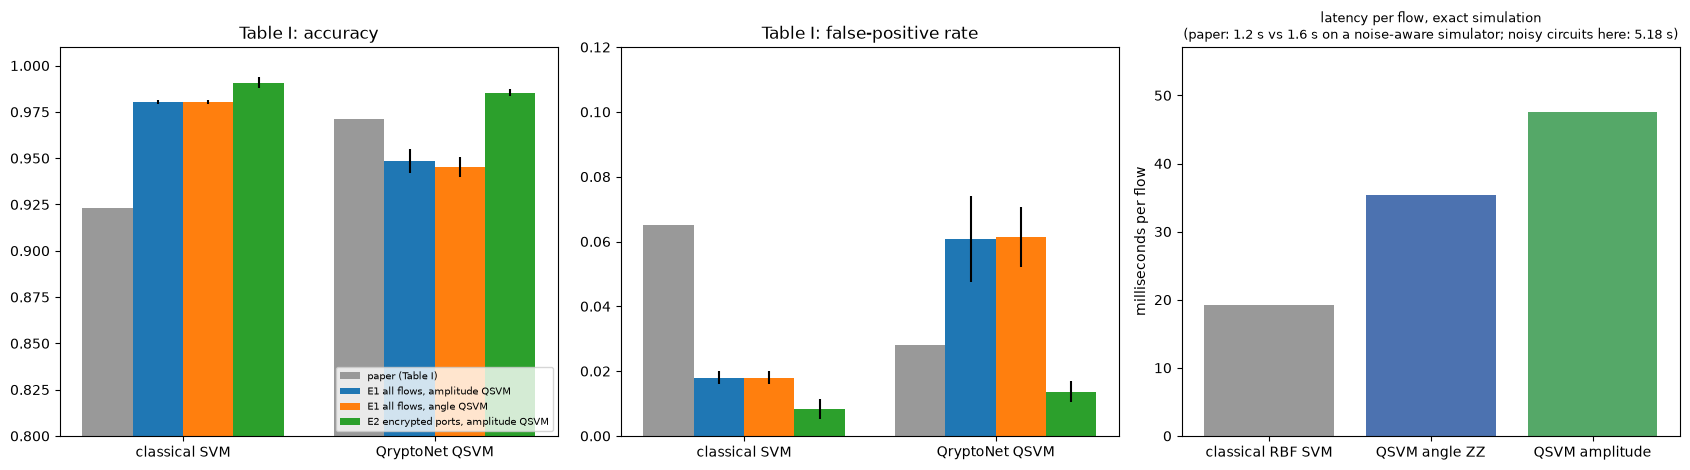

total notebook run time so far: 23.3 min


In [18]:
# The paper's Table I redrawn: accuracy and false-positive rate, paper vs this notebook (mean over seeds, error bars = std over seeds)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
labels = ["classical SVM", "QryptoNet QSVM"]
for k, (key, ttl, pv) in enumerate((("acc", "accuracy", (0.923, 0.971)), ("fpr", "false-positive rate", (0.065, 0.028)))):
    ax = axes[k]; w = 0.2; xs = np.arange(2)
    ax.bar(xs - 1.5 * w, pv, w, label="paper (Table I)", color="#999999")
    series = [("E1 all flows, amplitude QSVM", "E1", (SVM16, QA)), ("E1 all flows, angle QSVM", "E1", (SVM16, QZ)), ("E2 encrypted ports, amplitude QSVM", "E2", (SVM16, QA))]
    for j, (lab_, task, pair) in enumerate(series):
        ax.bar(xs + (j - 0.5) * w, [ours(task, m, key) for m in pair], w, yerr=[ours_sd(task, m, key) for m in pair], label=lab_)
    ax.set_xticks(xs); ax.set_xticklabels(labels); ax.set_title(f"Table I: {ttl}")
    if key == "acc": ax.set_ylim(0.8, 1.01); ax.legend(fontsize=7, loc="lower right")
    else: ax.set_ylim(0, max(0.12, 1.3 * RES[RES.model.isin([SVM16, QA, QZ])]["fpr"].max()))
ax = axes[2]
vals = [1000 * LAT["rbf"], 1000 * LAT["zz"], 1000 * LAT["amp"]]
ax.bar(["classical RBF SVM", "QSVM angle ZZ", "QSVM amplitude"], vals, color=["#999999", "#4c72b0", "#55a868"]); ax.set_ylim(0, 1.2 * max(vals)); ax.set_ylabel("milliseconds per flow")
ax.set_title(f"latency per flow, exact simulation\n(paper: 1.2 s vs 1.6 s on a noise-aware simulator; noisy circuits here: {LAT_NOISE:.2f} s)", fontsize=9)
plt.tight_layout(); plt.show()
print(f"total notebook run time so far: {(time.time() - NOTEBOOK_T0) / 60:.1f} min")

## Reading the paper critically

**What the data can and cannot support.** The paper says it parsed "encrypted sessions using TLS/SSL" from CIC-IDS2017 and lists TLS version and cipher suite among the features. The public flow CSVs contain neither: they are CICFlowMeter summaries without any handshake fields and without an encrypted flag. Using the destination port as a proxy (task E2) shows how thin the encrypted part of CIC-IDS2017 really is: apart from 5,897 SSH-Patator flows, 1,966 port-scan flows, 36 infiltration flows and 11 Heartbleed flows, everything that goes to a TLS or SSH port is benign. The attacks the paper names as "encrypted malware, botnet traffic" (Bot, DoS, DDoS, web attacks) have no flow at all to a TLS or SSH port in this dataset (the Botnet family has zero flows in `ENC_PORTS`). So the paper's 97 % cannot be a measurement on encrypted flows in any strict sense, and the sample size, split and exact flow selection are not stated.

**The headline claim, "the quantum kernel beats classical models", does not survive a fair baseline.** On all CIC-IDS2017 flows (E1) the best QSVM here reaches 94.8 % accuracy and a 6.1 % false-positive rate (paper: 97.1 % and 2.8 %), while an RBF SVM tuned on the same validation split reaches 98.0 % / 1.8 %, and a Random Forest 98.1 % / 1.5 %, on the same 16 features. Even on *identical inputs* the classical RBF SVM on the 16 amplitude vectors (97.9 %) is ahead of the amplitude QSVM (94.8 %). The paper's classical SVM (92.3 %, 6.5 % false-positive rate) looks like an untuned one: here the same RBF SVM on the 4 PCA angles gives 87.5 % with scikit-learn defaults and 96.2 % after a small search over `C` and `gamma`, a spread larger than the 4.8-point gap the paper reports, and a linear SVM on the amplitudes gives only 73.7 %. A comparison of one tuned kernel with one untuned kernel is a comparison of settings, not of kernels. On the easy encrypted-port task E2 the QSVMs and all tuned classical models sit between 97.9 % and 99.1 %, the QSVMs within 0.5 to 1.2 points of the best classical models; the paper's 97.1 % / 2.8 % is matched, but so it is by every classical model.

**Amplitude encoding is a cosine kernel.** For amplitude encoding the fidelity kernel is `(x . y)^2` of the two normalised vectors (Section 3 checks this against Qiskit): no entanglement, no feature space beyond the squared cosine similarity, evaluated in `O(d)` classically. The paper's statement that QSVM "reduces computational complexity to logarithmic time O(log N)" refers to a quantum-linear-algebra algorithm that needs QRAM; what is run here, as in the paper, is a simulator filling an `N x N` Gram matrix, whose cost grows quadratically with the number of training flows. Loading 16 amplitudes onto 4 qubits already needs a transpiled circuit of depth 45 with 11 CX gates (Figure 1), which is a hardware cost the paper's "4-qubit kernel depth" does not discuss. The angle-encoding variant with `zz_feature_map` is a genuine entangling kernel, but it is not better here either (94.5 % in E1) and its bandwidth must be tuned (without it the kernel collapses towards the identity).

**Latency.** The paper's 1.6 s versus 1.2 s per flow is a statement about an unnamed noise-aware simulator with an unknown training-set size. Here, exact simulation takes about 35 ms per flow for the angle QSVM against 19 ms for the classical SVM (1.8x; same direction as the paper's 1.3x), and the shot-based noisy-circuit simulation takes about 5 s per flow for only 40 training flows on a shared CPU. A circuit-based kernel needs one circuit per (test flow, support vector) pair, so per-flow latency grows linearly with the number of support vectors: the "under 2 s" figure depends on how many training flows the model keeps, which the paper does not say. In the small noise study the depolarising and readout noise raises the mean kernel error from 0.005 (shot noise alone) to 0.034, but with 40 training and 20 test flows the accuracy of all three kernels is identical, so no robustness claim can be drawn from it.

**Claims that cannot be tested.** The TLS compliance accuracy (99.9 %) and the covert-channel detection accuracy (94.3 % versus 78.2 %) come from a "post-quantum TLS verifier" and a "quantum entropy analyser" for which the paper gives neither an algorithm nor data. The entropy module is described as "quantum-inspired" Shannon / von Neumann entropy, i.e. classical statistics. These two rows of Table I are reported without evidence, and a rule-based cipher-suite checker reaching 99.9 % is not a machine-learning result at all.

**Internal inconsistencies.** The abstract says 97.3 % accuracy, Table I 97.1 %, the text "over 97 %", and Section III-C "above 99 %". The classical SVM and Random Forest "plateaued between 91 and 93 %" is not reproduced on any task here. Table I mentions 10-fold cross-validation but gives one number, with no variance. With the 1,200 test flows used here the standard error of an accuracy near 0.95 is about 0.6 points, so differences of one point between models are noise; the seed-to-seed standard deviations are printed in Section 4.

**Rare attack families.** The 11 infiltration test flows are the weak spot of every model, and the angle-encoding QSVM misses most of them (recall about 0.27 against 0.82 for the amplitude QSVM, 0.73 for the RBF SVM and 0.82 for the Random Forest on seed 42). With 11 flows that is a coarse number, but it shows how an overall accuracy hides the stealthy attacks the abstract emphasises ("stealthy, obfuscated, or zero-day attacks"); no experiment in the paper tests unseen attack types.

## Exercises

1. **Bandwidth and kernel collapse.** Set `BANDWIDTHS = [1.0]` (the angles used as they are). Look at the kernel heat-map of Section 5 and the training accuracy in Section 4: what happens to the off-diagonal kernel values, and why does the validation split pick a smaller bandwidth?
2. **Amplitude encoding is a cosine kernel.** Prove from the printed check in Section 3 that `K = (x . y)^2` for amplitude encoding, and replace the quantum kernel by `sklearn.metrics.pairwise.cosine_similarity(x, y) ** 2`. Do the predictions change at all? What does this say about the "high-dimensional Hilbert space" claim?
3. **Entanglement.** Change `ENTANGLEMENT` to `"full"` and `FM_REPS` to 1 or 3 and re-run (the NumPy simulator and the assertion against Qiskit adapt automatically). Does any setting beat the amplitude kernel by more than the seed-to-seed spread?
4. **A harder encrypted-traffic task.** Task E2 is dominated by SSH brute force. Restrict E2 to PortScan and Benign flows only (change `draw_task`) or hold out one attack family completely from training (zero-day style) and report the recall for the held-out family. Which models degrade?
5. **Statistical honesty.** Compute a 95 % confidence interval for the QSVM minus classical-SVM accuracy gap using the five seeds (`FAST_MODE = False`). Is the paper's 4.8-point gap distinguishable from zero on this data?
6. **Noise.** Raise `P2_DEPOL` to 0.05 or lower `SHOTS` to 256: how fast does the noisy kernel stop being positive semi-definite, and how does the SVM accuracy react?
7. **TLS fields.** CIC-IDS2017 has no TLS handshake metadata. Find a dataset that has it (for example, Zeek `ssl.log` fields) and describe how the 16-feature vector would change.